# Short-Horizon PM2.5 Forecasting at Marine Terrace, Singapore
**Predictive analytics / time-series forecasting** | single low-cost sensor | hourly data, April to August 2026

## Section 1. Project introduction

**Research question.** How accurately can hourly PM2.5 at Marine Terrace be forecast 1, 3 and 6 hours ahead, and do wind-direction and lagged daily-weather features improve predictions beyond historical PM2.5 alone?

**Target.** Hourly PM2.5 (µg/m³), observed value `h` hours after the forecast origin, for `h` in {1, 3, 6}.

**Data.**
| Source | Files | Used for |
|---|---|---|
| OpenAQ / AirGradient sensor, location 6301631 (Marine Terrace) | 5 monthly CSVs, April to August | PM2.5 target and history (`parameter == "pm25"` only) |
| Marina Barrage daily weather (station S108) | 5 monthly CSVs | Lagged rainfall and wind summaries (D-1 or earlier) |
| Hourly wind direction (station not named in the files) | 5 monthly CSVs | Wind direction as sine / cosine, shifted one hour for availability |

**Design in one paragraph.** Observed PM2.5 is placed on a complete hourly grid, and missing hours stay missing (target labels are never interpolated). Features use only information that exists at forecast time. The data are split chronologically 70 / 15 / 15 by target timestamp, with boundary-crossing samples purged. Two strong naive baselines (persistence and seasonal naive) are compared with Random Forest, HistGradientBoosting and ElasticNet, using three nested feature sets to test whether wind and weather add anything.

**Scope.** This is a single-location forecasting experiment. It is **not** a validated city-wide or transboundary-haze early-warning system. The limitations that matter most are listed again in Section 16.

**Limitations (stated up front).**
- One low-cost sensor; results apply to this location only. Calibration and humidity can bias optical PM2.5.
- The supplied PM2.5 files do not establish coverage of the October haze episode. Long outages reduce the usable observations.
- Daily weather is coarse in time and comes from another location. The wind station's identity and distance are unknown.
- No wind speed (hourly), fire-hotspot or satellite aerosol data are included.
- High-PM2.5 observations are too few for reliable spike detection; temporal autocorrelation reduces the effective sample size.

## Section 1b. Stakeholder, theme and dataset description

**Theme:** Energy and Environment (air quality). **Task type:** time-series forecasting (regression on a future value). **Unit of analysis:** one hourly observation of PM2.5 at one sensor.

**Stakeholder and decision context.** The primary audience is an **estate or facilities operations lead** (a Chief Operating Officer-level reader) responsible for outdoor activities and ventilation around Marine Terrace, who needs a short outlook of PM2.5 over the next hours. The secondary audience is an environmental agency (NEA) analyst who wants to know whether simple sensor-based forecasts add value over the latest reading. The forecast is meant to *support* hourly planning; it is not a regulatory alert.

**Predictive question.** How accurately can hourly PM2.5 at Marine Terrace be forecast 1, 3 and 6 hours ahead, and do wind direction and lagged daily weather improve on PM2.5 history alone?

**Sources** (the access date and registry entry must be completed by the group before submission):

| Dataset | Publisher / owner | Source | Files | Notes |
|---|---|---|---|---|
| Marine Terrace PM2.5, PM1, relative humidity, temperature, particle counts | AirGradient sensor, owner "Matt Ranostay", via **OpenAQ** (location 6301631) | https://explore.openaq.org/locations/6301631 | 5 monthly CSV exports, April to August 2026 | Secondary repository; original source is the AirGradient sensor feed. Only `parameter == "pm25"` is used. |
| Daily weather, station S108 (Marina Barrage) | Meteorological Service Singapore (MSS) | https://www.weather.gov.sg/climate-historical-daily/ | 5 monthly CSVs `DAILYDATA_S108_2026MM.csv` | Temperature columns are empty (checked in Section 8). |
| Hourly wind direction, Singapore (station not named in the files) | Aggregated from the data.gov.sg *Real-time weather readings, wind direction* API (`api-open.data.gov.sg/v2/real-time/api/wind-direction`) | https://data.gov.sg | 5 monthly CSVs `wind_direction_2026-MM_hourly.csv` | Hourly aggregation with `observation_count`; the contributing station and its distance from the sensor are not known. |

**Data dictionary (raw columns used).**

| Column | File | Meaning | Unit |
|---|---|---|---|
| `parameter` | OpenAQ | Measured quantity; only `pm25` is used | n/a |
| `value` | OpenAQ | Hourly PM2.5 concentration (**target**) | µg/m³ |
| `datetimeUtc`, `datetimeLocal` | OpenAQ | Time stamp of the reading; UTC is parsed and converted to Asia/Singapore | time |
| `Year`, `Month`, `Day` | MSS daily | Date of the daily summary | date |
| `Daily Rainfall Total (mm)` | MSS daily | Rainfall total for the day | mm |
| `Mean Wind Speed (km/h)`, `Max Wind Speed (km/h)` | MSS daily | Daily mean / maximum wind speed | km/h |
| `timestamp` | Wind | Start of the hour, with +08:00 offset | time |
| `observation_count` | Wind | Number of one-minute readings behind the hourly value | count |
| `wind_direction_deg` | Wind | Hourly wind direction, 0 to 360 degrees | degrees |

Engineered features are listed with their definitions and rationale in the **feature dictionary** (Section 9).

## Section 2. Imports and configuration
Everything that can be tuned or that encodes an assumption lives in this cell, so the experiment can be reproduced and audited.

In [1]:
import os, sys, json, random, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from scipy import stats
import sklearn
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

TZ = "Asia/Singapore"                    # all timestamps are converted to Singapore time
HORIZONS = [1, 3, 6]                     # forecast horizons in hours
MONTHS = ["04", "05", "06", "07", "08"]  # months supplied in the plan (April to August 2026)
MONTH_NAME = {"04": "april", "05": "may", "06": "june", "07": "july", "08": "august", "09": "september"}

# --- data preparation rules
FFILL_LIMIT = 6              # forward-fill gaps of at most 6 h, for INPUT history only (never for targets)
LONG_OUTAGE_H = 72           # a missing run longer than this is reported as a long outage
MAX_IMPUTED_24H = 6          # a sample is used only if at most 6 of the last 24 input hours were forward-filled
MIN_WIND_OBS = 30            # hourly wind direction needs at least 30 one-minute readings
ZERO_POLICY = "missing"      # exact 0.0 ug/m3 PM2.5 readings are treated as missing (see Section 5; sensitivity in Section 13b)

# --- features
LAGS = [1, 2, 3, 6, 12, 24]
ROLL_WINDOWS = [3, 6, 12, 24]

# --- split and evaluation
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15        # test = remaining 15 %
BOOT_BLOCK, N_BOOT, MIN_BOOT_N = 24, 2000, 120
NEA_ELEVATED = 55                        # NEA 1-hour PM2.5 band edge, used to define "high" episodes

# --- paths (relative to the project root)
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
FIG_DIR, TAB_DIR, MET_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "metrics"
for d in (DATA_DIR, FIG_DIR, TAB_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "openaq":  [f"openaq_location_6301631_measurments_{MONTH_NAME[m]}.csv" for m in MONTHS],
    "weather": [f"DAILYDATA_S108_2026{m}.csv" for m in MONTHS],
    "wind":    [f"wind_direction_2026-{m}_hourly.csv" for m in MONTHS],
}

# --- chart style: neutral surface, thin marks, quiet grid; categorical colours in a fixed order
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
C_BLUE, C_ORANGE, C_AQUA, C_MAG, C_VIOLET, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#6250d6", "#8a8984"
SPLIT_COL = {"train": C_BLUE, "val": C_ORANGE, "test": C_AQUA}
MCOL = {"Persistence": INK2, "Seasonal naive": "#bdbcb7", "RandomForest": C_BLUE, "HistGB": C_ORANGE, "ElasticNet": C_AQUA}
FS_COL = {"FS1": C_GREY, "FS2": C_MAG, "FS3": C_VIOLET}
matplotlib.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150,
})
def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()

print("Project root:", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| python", platform.python_version())

Project root: /home/claude/pm25-short-horizon-forecasting
pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | python 3.13.16


## Section 3. File inventory
Every expected file is located and opened. Missing files and load errors are **reported and stop the run**; nothing is skipped silently. On Colab, if the files are not found, the first cell offers an upload dialog (select all 15 files at once).

In [2]:
def _missing_expected():
    return [f for grp in EXPECTED.values() for f in grp if not (DATA_DIR / f).exists()]

if _missing_expected():
    try:
        from google.colab import files as _colab_files
        print("Expected files are missing. Upload all 15 CSV files (5 OpenAQ, 5 daily-weather, 5 wind-direction).")
        for name, content in _colab_files.upload().items():
            (DATA_DIR / name).write_bytes(content)
    except ImportError:
        pass

LOAD_ERRORS = []
def read_csv_safe(path):
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except Exception as e:
        LOAD_ERRORS.append((Path(path).name, repr(e)))
        return None

def date_range_of(role, df):
    if role == "openaq":
        t = pd.to_datetime(df["datetimeUtc"], utc=True, errors="coerce").dt.tz_convert(TZ)
    elif role == "wind":
        t = pd.to_datetime(df["timestamp"], utc=True, errors="coerce").dt.tz_convert(TZ)
    else:
        t = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=df["Day"]), errors="coerce")
    return t.min(), t.max()

FRAMES, inv = {k: [] for k in EXPECTED}, []
first_cols = {}
for role, files in EXPECTED.items():
    for f in files:
        p = DATA_DIR / f
        if not p.exists():
            inv.append({"file": f, "role": role, "status": "MISSING"}); FRAMES[role].append(None); continue
        df = read_csv_safe(p)
        if df is None:
            inv.append({"file": f, "role": role, "status": "LOAD ERROR"}); FRAMES[role].append(None); continue
        first_cols.setdefault(role, list(df.columns))
        t0, t1 = date_range_of(role, df)
        inv.append({"file": f, "role": role, "status": "ok", "rows": len(df), "n_columns": df.shape[1],
                    "same_columns_as_first_file": list(df.columns) == first_cols[role], "first": t0, "last": t1})
        FRAMES[role].append(df)

inventory = pd.DataFrame(inv)
display(inventory)
for role, cols in first_cols.items():
    print(f"{role:8s} columns: {cols}")

extra = sorted(p.name for p in DATA_DIR.glob("*.csv") if p.name not in {f for g in EXPECTED.values() for f in g})
print("\nCSV files present in data/ but not part of this experiment:", extra if extra else "none")
print("Missing expected files:", _missing_expected() or "none")
print("Load errors:", LOAD_ERRORS or "none")
assert not _missing_expected() and not LOAD_ERRORS, "Fix the missing / unreadable files above before continuing."

,file,role,status,rows,n_columns,same_columns_as_first_file,first,last
0,openaq_location_6301631_measurments_april.csv,openaq,ok,2280,15,True,2026-04-09 19:00:00+08:00,2026-04-28 22:00:00+08:00
1,openaq_location_6301631_measurments_may.csv,openaq,ok,1850,15,True,2026-05-15 22:00:00+08:00,2026-05-31 08:00:00+08:00
2,openaq_location_6301631_measurments_june.csv,openaq,ok,3480,15,True,2026-06-01 09:00:00+08:00,2026-06-30 08:00:00+08:00
3,openaq_location_6301631_measurments_july.csv,openaq,ok,3600,15,True,2026-07-01 09:00:00+08:00,2026-07-31 08:00:00+08:00
4,openaq_location_6301631_measurments_august.csv,openaq,ok,3580,15,True,2026-08-01 09:00:00+08:00,2026-08-31 08:00:00+08:00
5,DAILYDATA_S108_202604.csv,weather,ok,30,13,True,2026-04-01 00:00:00,2026-04-30 00:00:00
6,DAILYDATA_S108_202605.csv,weather,ok,31,13,True,2026-05-01 00:00:00,2026-05-31 00:00:00
7,DAILYDATA_S108_202606.csv,weather,ok,30,13,True,2026-06-01 00:00:00,2026-06-30 00:00:00
8,DAILYDATA_S108_202607.csv,weather,ok,31,13,True,2026-07-01 00:00:00,2026-07-31 00:00:00
9,DAILYDATA_S108_202608.csv,weather,ok,31,13,True,2026-08-01 00:00:00,2026-08-31 00:00:00


openaq   columns: ['location_id', 'location_name', 'parameter', 'value', 'unit', 'datetimeUtc', 'datetimeLocal', 'timezone', 'latitude', 'longitude', 'country_iso', 'isMobile', 'isMonitor', 'owner_name', 'provider']
weather  columns: ['Station', 'Year', 'Month', 'Day', 'Daily Rainfall Total (mm)', 'Highest 30 min Rainfall (mm)', 'Highest 60 min Rainfall (mm)', 'Highest 120 min Rainfall (mm)', 'Mean Temperature (°C)', 'Maximum Temperature (°C)', 'Minimum Temperature (°C)', 'Mean Wind Speed (km/h)', 'Max Wind Speed (km/h)']
wind     columns: ['timestamp', 'observation_count', 'wind_direction_deg']

CSV files present in data/ but not part of this experiment: none
Missing expected files: none
Load errors: none


## Section 4. Load OpenAQ measurements
Monthly files are combined and the original records are kept untouched (`raw_openaq_original`). Timestamps are parsed from the UTC column and converted to Singapore time; the local-time column is used only as a cross-check. PM2.5 is then selected with the `parameter` column.

In [3]:
raw_openaq = pd.concat([df.assign(source_file=f) for f, df in zip(EXPECTED["openaq"], FRAMES["openaq"])], ignore_index=True)
raw_openaq_original = raw_openaq.copy()          # preserved raw records

raw_openaq["time_utc"] = pd.to_datetime(raw_openaq["datetimeUtc"], utc=True, errors="coerce")
raw_openaq["time_sgt"] = raw_openaq["time_utc"].dt.tz_convert(TZ)

# timezone consistency: the local string (with its +08:00 offset) must describe the same instant as the UTC string
local_parsed = pd.to_datetime(raw_openaq["datetimeLocal"], utc=True, errors="coerce")
TZ_OK = bool((local_parsed == raw_openaq["time_utc"]).all())
offsets = raw_openaq["datetimeLocal"].str[-6:].value_counts()
print("Rows loaded:", len(raw_openaq), "| unparseable UTC timestamps:", int(raw_openaq["time_utc"].isna().sum()))
print("UTC and local timestamps describe the same instant in every row:", TZ_OK, "| local offsets present:", offsets.to_dict())
print("Locations:", raw_openaq[["location_id", "location_name"]].drop_duplicates().values.tolist(), "| provider:", raw_openaq["provider"].unique().tolist())

print("\nRecords per parameter, with units:")
display(raw_openaq.groupby("parameter").agg(records=("value", "size"), units=("unit", lambda s: ", ".join(sorted(s.dropna().unique())))))

pm_raw = raw_openaq[raw_openaq["parameter"] == "pm25"].copy()          # PM2.5 only, selected by the parameter column
print("\nPM2.5 records:", len(pm_raw), "| units:", pm_raw["unit"].unique().tolist())
cov = pm_raw.groupby("source_file").agg(records=("value", "size"), first=("time_sgt", "min"), last=("time_sgt", "max"))
display(cov)

Rows loaded: 14790 | unparseable UTC timestamps: 0
UTC and local timestamps describe the same instant in every row: True | local offsets present: {'+08:00': 14790}
Locations: [[6301631, 'Marine Terrace ']] | provider: ['AirGradient']

Records per parameter, with units:


,records,units
parameter,,
pm1,2958,µg/m³
pm25,2958,µg/m³
relativehumidity,2958,%
temperature,2958,c
um003,2958,particles/cm³



PM2.5 records: 2958 | units: ['µg/m³']


,records,first,last
source_file,,,
openaq_location_6301631_measurments_april.csv,456,2026-04-09 19:00:00+08:00,2026-04-28 22:00:00+08:00
openaq_location_6301631_measurments_august.csv,716,2026-08-01 09:00:00+08:00,2026-08-31 08:00:00+08:00
openaq_location_6301631_measurments_july.csv,720,2026-07-01 09:00:00+08:00,2026-07-31 08:00:00+08:00
openaq_location_6301631_measurments_june.csv,696,2026-06-01 09:00:00+08:00,2026-06-30 08:00:00+08:00
openaq_location_6301631_measurments_may.csv,370,2026-05-15 22:00:00+08:00,2026-05-31 08:00:00+08:00


## Section 5. Data-quality audit
Reported: record counts, non-numeric / zero / negative values, duplicates, missing hours and the longest missing runs, plus summary statistics. **High readings are not removed as outliers.** The treatment of exact zeros is argued from the evidence below and tested for sensitivity in Section 13b.

In [4]:
def missing_runs(s):
    """Consecutive missing hours in an hourly Series -> DataFrame(start, end, hours)."""
    isn = s.isna()
    grp = (isn != isn.shift()).cumsum()
    rows = []
    for _, g in isn[isn].groupby(grp[isn]):
        rows.append({"start": g.index[0], "end": g.index[-1], "hours": len(g)})
    return pd.DataFrame(rows, columns=["start", "end", "hours"])

v_raw = pm_raw["value"]
v = pd.to_numeric(v_raw, errors="coerce")
n_null = int(v_raw.isna().sum())
n_nonnumeric = int(v.isna().sum() - n_null)
rec_hour = pm_raw["time_sgt"].dt.floor("h")
grid = pd.date_range(rec_hour.min(), rec_hour.max(), freq="h")
present = pd.Series(1.0, index=grid).where(grid.isin(pd.DatetimeIndex(rec_hour.unique())))
runs_norecord = missing_runs(present)

audit = {
    "pm25_records": len(pm_raw),
    "null_values": n_null,
    "non_numeric_values": n_nonnumeric,
    "exact_zero_values": int((v == 0).sum()),
    "negative_values": int((v < 0).sum()),
    "duplicate_timestamps_exact": int(pm_raw.duplicated("time_utc").sum()),
    "duplicate_hours": int(rec_hour.duplicated().sum()),
    "timestamps_not_on_the_hour": int(((pm_raw["time_sgt"].dt.minute != 0) | (pm_raw["time_sgt"].dt.second != 0)).sum()),
    "first_record_sgt": str(pm_raw["time_sgt"].min()),
    "last_record_sgt": str(pm_raw["time_sgt"].max()),
    "hours_in_span": len(grid),
    "hours_with_a_record": int(present.notna().sum()),
    "hours_without_any_record": int(present.isna().sum()),
    "pct_hours_without_any_record": round(100 * present.isna().mean(), 2),
    "number_of_missing_runs": len(runs_norecord),
    "longest_missing_run_hours": int(runs_norecord["hours"].max()) if len(runs_norecord) else 0,
    "readings_above_55": int((v > NEA_ELEVATED).sum()),
    "readings_above_150": int((v > 150).sum()),
}
desc = v.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
for k, val in desc.items():
    audit[f"stat_{k}"] = round(float(val), 3)
dq_summary = pd.DataFrame({"metric": list(audit.keys()), "value": list(audit.values())})
display(dq_summary)

print("\nLongest missing runs (hours without any PM2.5 record):")
display(runs_norecord.sort_values("hours", ascending=False).head(8).reset_index(drop=True))
print("Ten highest readings (kept, not treated as outliers):")
display(pm_raw.assign(value=v).nlargest(10, "value")[["time_sgt", "value"]].reset_index(drop=True))

,metric,value
0,pm25_records,2958
1,null_values,0
2,non_numeric_values,0
3,exact_zero_values,24
4,negative_values,0
5,duplicate_timestamps_exact,0
6,duplicate_hours,0
7,timestamps_not_on_the_hour,0
8,first_record_sgt,2026-04-09 19:00:00+08:00
9,last_record_sgt,2026-08-31 08:00:00+08:00



Longest missing runs (hours without any PM2.5 record):


,start,end,hours
0,2026-04-28 23:00:00+08:00,2026-05-15 21:00:00+08:00,407
1,2026-05-31 09:00:00+08:00,2026-06-01 08:00:00+08:00,24
2,2026-07-31 09:00:00+08:00,2026-08-01 08:00:00+08:00,24
3,2026-06-30 09:00:00+08:00,2026-07-01 08:00:00+08:00,24
4,2026-08-17 12:00:00+08:00,2026-08-17 14:00:00+08:00,3
5,2026-04-16 15:00:00+08:00,2026-04-16 16:00:00+08:00,2
6,2026-04-18 15:00:00+08:00,2026-04-18 15:00:00+08:00,1
7,2026-04-24 13:00:00+08:00,2026-04-24 13:00:00+08:00,1


Ten highest readings (kept, not treated as outliers):


,time_sgt,value
0,2026-05-17 01:00:00+08:00,292.6
1,2026-05-26 09:00:00+08:00,224.1
2,2026-06-08 19:00:00+08:00,213.8
3,2026-04-25 18:00:00+08:00,160.2
4,2026-06-08 20:00:00+08:00,145.9
5,2026-05-20 10:00:00+08:00,141.3
6,2026-07-07 00:00:00+08:00,140.4
7,2026-08-18 18:00:00+08:00,130.6
8,2026-04-27 09:00:00+08:00,124.2
9,2026-05-30 11:00:00+08:00,107.0


In [5]:
# Are exact zeros plausible air readings or sensor dropouts?  Look at the neighbouring hours and the other channels.
wide_raw = raw_openaq.pivot_table(index="time_utc", columns="parameter", values="value", aggfunc="median")
pm_by_time = wide_raw["pm25"]
zero_times = pm_raw.loc[v == 0, "time_utc"]
ctx = []
for t in zero_times:
    ctx.append({"time_sgt": t.tz_convert(TZ), "prev_hour_pm25": pm_by_time.get(t - pd.Timedelta(hours=1)),
                "next_hour_pm25": pm_by_time.get(t + pd.Timedelta(hours=1)),
                "pm1_same_hour": wide_raw.loc[t, "pm1"], "particle_count_um003": wide_raw.loc[t, "um003"]})
zero_ctx = pd.DataFrame(ctx)
display(zero_ctx)
ref_level = float(v[v > 0].median())
both_normal = ((zero_ctx["prev_hour_pm25"] > 5) & (zero_ctx["next_hour_pm25"] > 5)).sum() if len(zero_ctx) else 0
print(f"Median of the non-zero readings: {ref_level:.1f} ug/m3")
print(f"{len(zero_ctx)} exact zeros; {both_normal} have BOTH neighbouring hours above 5 ug/m3; "
      f"{int((zero_ctx['pm1_same_hour'] == 0).sum())} also read PM1 = 0.")

,time_sgt,prev_hour_pm25,next_hour_pm25,pm1_same_hour,particle_count_um003
0,2026-04-15 20:00:00+08:00,0.3,0.1,0.0,109.0
1,2026-04-15 22:00:00+08:00,0.1,3.7,0.0,119.0
2,2026-04-17 18:00:00+08:00,1.0,0.0,0.0,105.0
3,2026-04-17 19:00:00+08:00,0.0,0.0,0.0,90.0
4,2026-04-17 20:00:00+08:00,0.0,0.1,0.0,52.0
5,2026-04-19 20:00:00+08:00,3.4,0.3,0.0,114.0
6,2026-05-17 06:00:00+08:00,0.9,0.1,0.0,131.0
7,2026-05-20 02:00:00+08:00,0.7,0.4,0.0,146.0
8,2026-05-20 05:00:00+08:00,0.2,0.2,0.0,146.0
9,2026-05-28 11:00:00+08:00,9.5,0.0,0.0,89.0


Median of the non-zero readings: 20.8 ug/m3
24 exact zeros; 0 have BOTH neighbouring hours above 5 ug/m3; 24 also read PM1 = 0.


**Decision on zeros.** An hourly mean of exactly 0.0 µg/m³ is not plausible for ambient air in Singapore, and the table above shows zeros that sit next to ordinary readings (and usually coincide with PM1 = 0), which is the signature of a sensor dropout or warm-up value rather than clean air. The default is therefore to treat exact zeros as **missing**. Because that is a judgement call, Section 13b re-runs persistence and a model with zeros kept as valid readings. No high reading is removed.

## Section 6. Construct the hourly target series
Duplicate timestamps are aggregated with the **median**, the grid is made complete, and gaps stay missing. `pm_obs` is the observed-only series: it is the only source of target labels, and it is never interpolated or filled.

In [6]:
def make_hourly(pm_df, zero_policy="missing"):
    """Hourly observed PM2.5 on a complete grid. Missing hours remain NaN."""
    d = pm_df[["time_sgt", "value"]].copy()
    d["value"] = pd.to_numeric(d["value"], errors="coerce")
    d.loc[d["value"] < 0, "value"] = np.nan                 # negative PM is physically impossible
    if zero_policy == "missing":
        d.loc[d["value"] == 0, "value"] = np.nan            # exact zeros treated as dropouts (Section 5)
    d["hour"] = d["time_sgt"].dt.floor("h")
    s = d.groupby("hour")["value"].median()                 # duplicates -> median
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="h"))
    s.index.name = "time_sgt"
    return s

pm_obs = make_hourly(pm_raw, ZERO_POLICY)
gaps = missing_runs(pm_obs)
gaps["category"] = np.where(gaps["hours"] > LONG_OUTAGE_H, f"long outage (> {LONG_OUTAGE_H} h)",
                    np.where(gaps["hours"] > FFILL_LIMIT, f"gap longer than the {FFILL_LIMIT} h fill limit",
                             f"short gap (<= {FFILL_LIMIT} h, fillable for inputs)"))
print(f"Hourly grid: {len(pm_obs)} hours from {pm_obs.index.min()} to {pm_obs.index.max()}")
print(f"Observed: {int(pm_obs.notna().sum())} h ({100 * pm_obs.notna().mean():.1f} %) | missing: {int(pm_obs.isna().sum())} h")
print("\nMissing runs by category:")
display(gaps.groupby("category")["hours"].agg(runs="size", total_hours="sum", longest="max"))
print("All gaps longer than the fill limit:")
display(gaps[gaps["hours"] > FFILL_LIMIT].sort_values("start").reset_index(drop=True))
LONG = gaps[gaps["hours"] > LONG_OUTAGE_H]
for _, g in LONG.iterrows():
    print(f"LONG OUTAGE: {g['start']:%Y-%m-%d %H:%M} to {g['end']:%Y-%m-%d %H:%M} ({g['hours']} h = {g['hours'] / 24:.1f} days)")

Hourly grid: 3446 hours from 2026-04-09 19:00:00+08:00 to 2026-08-31 08:00:00+08:00
Observed: 2934 h (85.1 %) | missing: 512 h

Missing runs by category:


,runs,total_hours,longest
category,,,
gap longer than the 6 h fill limit,3,72,24
long outage (> 72 h),1,407,407
"short gap (<= 6 h, fillable for inputs)",24,33,3


All gaps longer than the fill limit:


,start,end,hours,category
0,2026-04-28 23:00:00+08:00,2026-05-15 21:00:00+08:00,407,long outage (> 72 h)
1,2026-05-31 09:00:00+08:00,2026-06-01 08:00:00+08:00,24,gap longer than the 6 h fill limit
2,2026-06-30 09:00:00+08:00,2026-07-01 08:00:00+08:00,24,gap longer than the 6 h fill limit
3,2026-07-31 09:00:00+08:00,2026-08-01 08:00:00+08:00,24,gap longer than the 6 h fill limit


LONG OUTAGE: 2026-04-28 23:00 to 2026-05-15 21:00 (407 h = 17.0 days)


The three 24-hour gaps (31 May to 1 June, 30 June to 1 July, 31 July to 1 August) sit exactly at month boundaries: each monthly file ends at 08:00 Singapore time on the last day and the next starts at 09:00 on the 1st, which looks like an **export-window artifact** rather than a sensor fault. The 407-hour gap between the April and May files (28 April 23:00 to 15 May 21:00) is a real sensor outage in the supplied data. Neither is repaired; samples whose 24 h history would cross them are dropped.

## Section 7. Process wind direction
Steps: combine the monthly files, convert to Singapore time, check duplicates and missing values, set direction to missing when fewer than 30 one-minute readings back an hour, **shift the availability forward by one hour** (the value stamped `H` summarises the hour starting at `H` and is complete only at `H + 1 h`), then encode the angle as sine and cosine. Sine / cosine handle the circular scale (359° and 1° are neighbours).

In [7]:
wd_raw = pd.concat(FRAMES["wind"], ignore_index=True)
wd = wd_raw.copy()
wd["time_sgt"] = pd.to_datetime(wd["timestamp"], utc=True, errors="coerce").dt.tz_convert(TZ)

print("Rows:", len(wd), "| unparseable timestamps:", int(wd["time_sgt"].isna().sum()))
print("Duplicate timestamps:", int(wd["time_sgt"].duplicated().sum()), "| missing direction values:", int(wd["wind_direction_deg"].isna().sum()))
print("Direction range:", round(wd["wind_direction_deg"].min(), 2), "to", round(wd["wind_direction_deg"].max(), 2), "degrees")
print("Readings per hour (observation_count):")
display(wd["observation_count"].describe().round(2).to_frame().T)
print(f"Hours with fewer than {MIN_WIND_OBS} readings:", int((wd["observation_count"] < MIN_WIND_OBS).sum()))

wd = wd.sort_values(["time_sgt", "observation_count"], ascending=[True, False]).drop_duplicates("time_sgt").set_index("time_sgt")
wd_dir = wd["wind_direction_deg"].where(wd["observation_count"] >= MIN_WIND_OBS)
wd_dir = wd_dir.reindex(pd.date_range(wd_dir.index.min(), wd_dir.index.max(), freq="h"))
print(f"\nHourly wind direction: {wd_dir.index.min()} -> {wd_dir.index.max()} | valid hours: {int(wd_dir.notna().sum())} | missing: {int(wd_dir.isna().sum())}")
print("Wind coverage starts before and ends after the PM2.5 series:",
      bool(wd_dir.index.min() <= pm_obs.index.min() and wd_dir.index.max() >= pm_obs.index.max()))

def build_wind_features(direction):
    """Direction (deg) stamped at hour start -> sine / cosine indexed by the time they become available (+1 h)."""
    avail = direction.copy()
    avail.index = avail.index + pd.Timedelta(hours=1)
    rad = np.deg2rad(avail)
    return pd.DataFrame({"wind_sin": np.sin(rad), "wind_cos": np.cos(rad)})

wind_feat = build_wind_features(wd_dir)
t_chk = pm_obs.index[1000]
assert np.isclose(wind_feat.loc[t_chk, "wind_sin"], np.sin(np.deg2rad(wd_dir.loc[t_chk - pd.Timedelta(hours=1)])), equal_nan=True)
print("\nAvailability check passed: the wind feature at", t_chk, "is built from the hour stamped", t_chk - pd.Timedelta(hours=1))

Rows: 3672 | unparseable timestamps: 0
Duplicate timestamps: 0 | missing direction values: 1
Direction range: 0.06 to 359.92 degrees
Readings per hour (observation_count):


,count,mean,std,min,25%,50%,75%,max
observation_count,3672.0,59.69,2.43,0.0,60.0,60.0,60.0,60.0


Hours with fewer than 30 readings: 9

Hourly wind direction: 2026-04-01 00:00:00+08:00 -> 2026-08-31 23:00:00+08:00 | valid hours: 3663 | missing: 9
Wind coverage starts before and ends after the PM2.5 series: True

Availability check passed: the wind feature at 2026-05-21 11:00:00+08:00 is built from the hour stamped 2026-05-21 10:00:00+08:00


## Section 8. Process daily weather
Year / Month / Day are parsed, `-` placeholders become missing, and the variables that actually contain data are identified. A day's summary is complete only when the day has ended, so a forecast made on day `D` may use days `D-1` and earlier only.

In [8]:
wx = pd.concat(FRAMES["weather"], ignore_index=True)
wx.columns = [c.strip() for c in wx.columns]
wx["date"] = pd.to_datetime(dict(year=wx["Year"], month=wx["Month"], day=wx["Day"]))
value_cols = [c for c in wx.columns if c not in ("Station", "Year", "Month", "Day", "date")]
for c in value_cols:
    wx[c] = pd.to_numeric(wx[c].astype(str).str.strip().replace({"-": np.nan, "": np.nan}), errors="coerce")

print("Station:", wx["Station"].unique().tolist(), "|", wx["date"].min().date(), "->", wx["date"].max().date(), "|", len(wx), "days")
print("Duplicate days:", int(wx["date"].duplicated().sum()), "| calendar days missing:",
      len(pd.date_range(wx["date"].min(), wx["date"].max()).difference(wx["date"])))
avail_tbl = pd.DataFrame({"non_missing_days": wx[value_cols].notna().sum(), "pct_available": (100 * wx[value_cols].notna().mean()).round(1)})
display(avail_tbl)
temp_cols = [c for c in value_cols if "Temperature" in c]
print("Temperature columns with any valid value:", [c for c in temp_cols if wx[c].notna().any()] or "none -> temperature is NOT usable from this file")

d_base = (wx.set_index("date").sort_index()
            .rename(columns={"Daily Rainfall Total (mm)": "rain", "Mean Wind Speed (km/h)": "wind_mean", "Max Wind Speed (km/h)": "wind_max"})
            [["rain", "wind_mean", "wind_max"]])
d_base = d_base.reindex(pd.date_range(d_base.index.min(), d_base.index.max(), freq="D"))
display(d_base.describe().round(2).T)

def build_weather_features(daily):
    """Daily summaries -> features indexed by the first date on which they may be used (day D is usable from D+1)."""
    f = pd.DataFrame(index=daily.index)
    f["wx_rain_d1"] = daily["rain"]
    f["wx_rain_sum3d"] = daily["rain"].rolling(3, min_periods=3).sum()
    f["wx_wind_mean_d1"] = daily["wind_mean"]
    f["wx_wind_max_d1"] = daily["wind_max"]
    f.index = f.index + pd.Timedelta(days=1)
    return f

wx_feat = build_weather_features(d_base)
print("\nWeather features are first available on", wx_feat.index.min().date(), "(one day after the first summary).")

Station: ['Marina Barrage'] | 2026-04-01 -> 2026-08-31 | 153 days
Duplicate days: 0 | calendar days missing: 0


,non_missing_days,pct_available
Daily Rainfall Total (mm),153,100.0
Highest 30 min Rainfall (mm),153,100.0
Highest 60 min Rainfall (mm),153,100.0
Highest 120 min Rainfall (mm),153,100.0
Mean Temperature (°C),0,0.0
Maximum Temperature (°C),0,0.0
Minimum Temperature (°C),0,0.0
Mean Wind Speed (km/h),153,100.0
Max Wind Speed (km/h),153,100.0


Temperature columns with any valid value: none -> temperature is NOT usable from this file


,count,mean,std,min,25%,50%,75%,max
rain,153.0,4.15,9.67,0.0,0.0,0.0,2.6,65.8
wind_mean,153.0,5.02,1.08,2.7,4.1,5.0,5.9,7.5
wind_max,153.0,26.23,6.45,13.5,21.9,24.8,30.2,50.5



Weather features are first available on 2026-04-02 (one day after the first summary).


In [9]:
summ = pd.DataFrame([
    {"dataset": "PM2.5 (OpenAQ, target)", "observation unit": "hourly mean at one sensor", "rows (raw)": len(pm_raw), "hourly grid hours": len(pm_obs), "observed hours": int(pm_obs.notna().sum()),
     "from": pm_obs.index.min(), "to": pm_obs.index.max()},
    {"dataset": "Wind direction (hourly)", "observation unit": "hourly direction", "rows (raw)": len(wd_raw), "hourly grid hours": len(wd_dir), "observed hours": int(wd_dir.notna().sum()),
     "from": wd_dir.index.min(), "to": wd_dir.index.max()},
    {"dataset": "Daily weather (S108)", "observation unit": "daily summary", "rows (raw)": len(wx), "hourly grid hours": np.nan, "observed hours": np.nan,
     "from": wx["date"].min(), "to": wx["date"].max()}])
display(summ)
print("Target:", "PM2.5 at t+h, h in", HORIZONS, "| potential predictors: FS1 =", len(FEATURE_SETS["FS1"]) if "FEATURE_SETS" in globals() else 21, "history/time features, + 2 wind, + 4 weather (Section 9).")

,dataset,observation unit,rows (raw),hourly grid hours,observed hours,from,to
0,"PM2.5 (OpenAQ, target)",hourly mean at one sensor,2958,3446.0,2934.0,2026-04-09 19:00:00+08:00,2026-08-31 08:00:00+08:00
1,Wind direction (hourly),hourly direction,3672,3672.0,3663.0,2026-04-01 00:00:00+08:00,2026-08-31 23:00:00+08:00
2,Daily weather (S108),daily summary,153,NaN,NaN,2026-04-01 00:00:00,2026-08-31 00:00:00


Target: PM2.5 at t+h, h in [1, 3, 6] | potential predictors: FS1 = 21 history/time features, + 2 wind, + 4 weather (Section 9).


## Section 8b. Exploratory data analysis
The EDA is restricted to what **informs modelling choices**: how persistent PM2.5 is (and therefore how strong a persistence baseline will be), whether there is a daily cycle (hour-of-day features), whether wind direction or lagged rain separates PM2.5 levels (external features). Everything uses observed values only.

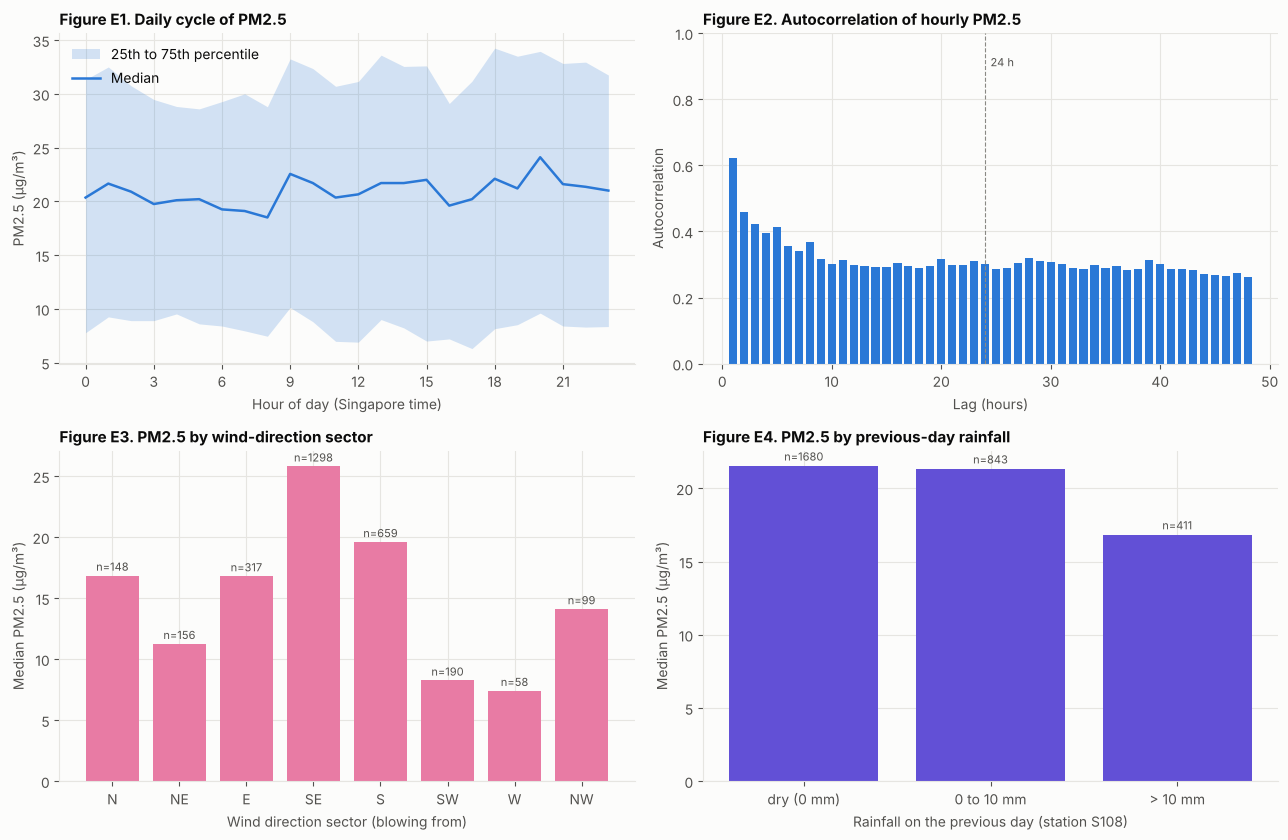

,feature,spearman_with_pm25,n
0,wx_rain_d1,-0.083,2934
1,wx_rain_sum3d,-0.118,2934
2,wx_wind_mean_d1,0.240,2934
3,wx_wind_max_d1,0.042,2934


In [10]:
obs = pm_obs.dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) diurnal profile
g = obs.groupby(obs.index.hour)
med, q25, q75 = g.median(), g.quantile(0.25), g.quantile(0.75)
ax = axes[0, 0]
ax.fill_between(med.index, q25, q75, color=C_BLUE, alpha=0.2, lw=0, label="25th to 75th percentile")
ax.plot(med.index, med, color=C_BLUE, lw=1.8, label="Median")
ax.set_xlabel("Hour of day (Singapore time)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("Figure E1. Daily cycle of PM2.5"); ax.legend(); ax.set_xticks(range(0, 24, 3))

# (b) autocorrelation
lags = np.arange(1, 49)
acf = np.array([pm_obs.corr(pm_obs.shift(int(k))) for k in lags])
ax = axes[0, 1]
ax.bar(lags, acf, color=C_BLUE, width=0.75)
ax.axvline(24, color=C_GREY, lw=0.8, ls="--"); ax.text(24.5, 0.9, "24 h", color=INK2, fontsize=8)
ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Autocorrelation"); ax.set_title("Figure E2. Autocorrelation of hourly PM2.5"); ax.set_ylim(0, 1)

# (c) wind-direction sector (value available at the hour, i.e. stamped one hour earlier)
ang = wd_dir.copy(); ang.index = ang.index + pd.Timedelta(hours=1)
ang = ang.reindex(pm_obs.index)
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
sector = (((ang + 22.5) // 45) % 8)
dfw = pd.DataFrame({"pm": pm_obs, "sec": sector}).dropna()
sec_med = dfw.groupby("sec")["pm"].median().reindex(range(8)); sec_n = dfw.groupby("sec").size().reindex(range(8)).fillna(0).astype(int)
ax = axes[1, 0]
ax.bar(names, sec_med.values, color=C_MAG)
for i, (v_, n_) in enumerate(zip(sec_med.values, sec_n.values)):
    ax.text(i, (0 if np.isnan(v_) else v_) + 0.4, f"n={n_}", ha="center", fontsize=8, color=INK2)
ax.set_xlabel("Wind direction sector (blowing from)"); ax.set_ylabel("Median PM2.5 (µg/m³)"); ax.set_title("Figure E3. PM2.5 by wind-direction sector")

# (d) lagged daily rainfall category
rain = wx_feat["wx_rain_d1"].reindex(pm_obs.index.tz_localize(None).normalize()).to_numpy()
cat = pd.cut(pd.Series(rain, index=pm_obs.index), [-0.01, 0.0, 10, 1e9], labels=["dry (0 mm)", "0 to 10 mm", "> 10 mm"])
dfr = pd.DataFrame({"pm": pm_obs, "cat": cat}).dropna()
rmed, rn = dfr.groupby("cat", observed=True)["pm"].median(), dfr.groupby("cat", observed=True).size()
ax = axes[1, 1]
ax.bar(rmed.index.astype(str), rmed.values, color=C_VIOLET)
for i, (v_, n_) in enumerate(zip(rmed.values, rn.values)):
    ax.text(i, v_ + 0.4, f"n={n_}", ha="center", fontsize=8, color=INK2)
ax.set_xlabel("Rainfall on the previous day (station S108)"); ax.set_ylabel("Median PM2.5 (µg/m³)"); ax.set_title("Figure E4. PM2.5 by previous-day rainfall")
fig.tight_layout(); save_fig(fig, "figE_eda_overview.png")

# Spearman correlations of hourly PM2.5 with the lagged daily features
corr_rows = []
for c in WEATHER if "WEATHER" in globals() else ["wx_rain_d1", "wx_rain_sum3d", "wx_wind_mean_d1", "wx_wind_max_d1"]:
    s_ = pd.DataFrame({"pm": pm_obs, "x": wx_feat[c].reindex(pm_obs.index.tz_localize(None).normalize()).to_numpy()}).dropna()
    corr_rows.append({"feature": c, "spearman_with_pm25": stats.spearmanr(s_["pm"], s_["x"])[0], "n": len(s_)})
corr_tbl = pd.DataFrame(corr_rows)
display(corr_tbl.round(3))
EDA_FACTS = {"acf1": acf[0], "acf6": acf[5], "acf24": acf[23], "diurnal_range": float(med.max() - med.min()), "peak_hour": int(med.idxmax()), "trough_hour": int(med.idxmin()),
             "sector_range": float(sec_med.max() - sec_med.min()), "sector_hi": names[int(sec_med.idxmax())], "sector_lo": names[int(sec_med.idxmin())], "sector_min_n": int(sec_n[sec_n > 0].min())}

In [11]:
f = EDA_FACTS
display(Markdown(
f"**What the EDA tells us for modelling.**\n"
f"- *Persistence.* Autocorrelation falls from {f['acf1']:.2f} at lag 1 h to {f['acf6']:.2f} at 6 h and {f['acf24']:.2f} at 24 h: recent values are informative mainly at short horizons, so a persistence baseline is the natural benchmark and lag / rolling features are the natural inputs.\n"
f"- *Daily cycle.* The hourly median varies by only {f['diurnal_range']:.1f} µg/m³ over the day (peak near {f['peak_hour']:02d}:00, lowest near {f['trough_hour']:02d}:00) against a wide inter-quartile band, so the cycle is modest; hour-of-day features are included but are not expected to carry much.\n"
f"- *Wind direction.* In raw terms the sector medians differ a lot ({f['sector_range']:.1f} µg/m³; highest with wind from {f['sector_hi']}, lowest from {f['sector_lo']}). This is **not** evidence that wind helps a forecast: wind direction is confounded with the time of year (some sectors dominate particular months) and PM2.5 drifted upward over the period, and sectors have unequal sample sizes (smallest n={f['sector_min_n']}). The ablation tests whether wind adds anything *after* PM2.5 history is known.\n"
f"- *Lagged daily weather* is coarse (one value per day from another station) and its rank correlations with hourly PM2.5 are small (table above)."
))

**What the EDA tells us for modelling.**
- *Persistence.* Autocorrelation falls from 0.62 at lag 1 h to 0.36 at 6 h and 0.30 at 24 h: recent values are informative mainly at short horizons, so a persistence baseline is the natural benchmark and lag / rolling features are the natural inputs.
- *Daily cycle.* The hourly median varies by only 5.6 µg/m³ over the day (peak near 20:00, lowest near 08:00) against a wide inter-quartile band, so the cycle is modest; hour-of-day features are included but are not expected to carry much.
- *Wind direction.* In raw terms the sector medians differ a lot (18.4 µg/m³; highest with wind from SE, lowest from W). This is **not** evidence that wind helps a forecast: wind direction is confounded with the time of year (some sectors dominate particular months) and PM2.5 drifted upward over the period, and sectors have unequal sample sizes (smallest n=58). The ablation tests whether wind adds anything *after* PM2.5 history is known.
- *Lagged daily weather* is coarse (one value per day from another station) and its rank correlations with hourly PM2.5 are small (table above).

## Section 9. Feature engineering
Every feature is computed from information available at the forecast origin `t`.

- **PM2.5 history:** current available value, lags of 1, 2, 3, 6, 12 and 24 h, rolling means and standard deviations over 3, 6, 12 and 24 h (trailing windows that must be complete).
- **Time:** hour of day, day of week, and their sine / cosine encodings.
- **External:** wind direction (sine, cosine) of the last *completed* hour; lagged daily rainfall (yesterday, 3-day sum) and wind speed (yesterday's mean and maximum).
- **Imputation policy:** PM2.5 *inputs* are forward-filled for gaps of at most 6 h, which equals "the latest available measurement". Filled hours are flagged, a sample is used only if at most 6 of the last 24 input hours were filled, and longer outages stay missing so that no feature window silently crosses an outage. Targets are never filled.

In [12]:
HIST = ["pm_now"] + [f"pm_lag{k}" for k in LAGS] + [f"pm_mean{w}" for w in ROLL_WINDOWS] + [f"pm_std{w}" for w in ROLL_WINDOWS]
TIME = ["hour", "dow", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
WIND = ["wind_sin", "wind_cos"]
WEATHER = ["wx_rain_d1", "wx_rain_sum3d", "wx_wind_mean_d1", "wx_wind_max_d1"]
FEATURE_SETS = {"FS1": HIST + TIME,
                "FS2": HIST + TIME + WIND,
                "FS3": HIST + TIME + WIND + WEATHER}
FS_LABEL = {"FS1": "FS1: PM2.5 history + time", "FS2": "FS2: + wind direction", "FS3": "FS3: + lagged daily weather"}

def build_features(pm_series, wind_f, wx_f, input_delay=0):
    """Feature matrix X (one row per hourly origin) and bookkeeping flags. input_delay=1 treats the PM stamp as hour-START."""
    idx = pm_series.index
    pm_in = pm_series.shift(input_delay) if input_delay else pm_series.copy()
    pm_fill = pm_in.ffill(limit=FFILL_LIMIT)                      # input history only; never used for targets
    imputed = (pm_in.isna() & pm_fill.notna()).astype(int)
    X = pd.DataFrame(index=idx)
    X["pm_now"] = pm_fill
    for k in LAGS:
        X[f"pm_lag{k}"] = pm_fill.shift(k)
    for w in ROLL_WINDOWS:
        X[f"pm_mean{w}"] = pm_fill.rolling(w, min_periods=w).mean()
        X[f"pm_std{w}"] = pm_fill.rolling(w, min_periods=w).std()
    X["hour"], X["dow"] = idx.hour, idx.dayofweek
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * idx.hour / 24), np.cos(2 * np.pi * idx.hour / 24)
    X["dow_sin"], X["dow_cos"] = np.sin(2 * np.pi * idx.dayofweek / 7), np.cos(2 * np.pi * idx.dayofweek / 7)
    X["wind_sin"], X["wind_cos"] = wind_f["wind_sin"].reindex(idx), wind_f["wind_cos"].reindex(idx)
    dates = idx.tz_localize(None).normalize()
    for c in wx_f.columns:
        X[c] = wx_f[c].reindex(dates).values
    meta = pd.DataFrame({"pm_now_imputed": imputed, "imputed_hours_24h": imputed.rolling(24, min_periods=1).sum()}, index=idx)
    return X, meta

X_all, META = build_features(pm_obs, wind_feat, wx_feat)
print("Feature matrix:", X_all.shape, "| feature sets:", {k: len(v) for k, v in FEATURE_SETS.items()})
display(X_all.describe().T[["count", "mean", "std", "min", "max"]].round(3).head(40))

Feature matrix: (3446, 27) | feature sets: {'FS1': 21, 'FS2': 23, 'FS3': 27}


,count,mean,std,min,max
pm_now,2991.0,21.286,16.824,0.100,292.600
pm_lag1,2990.0,21.292,16.824,0.100,292.600
pm_lag2,2989.0,21.290,16.827,0.100,292.600
pm_lag3,2988.0,21.288,16.829,0.100,292.600
pm_lag6,2985.0,21.277,16.834,0.100,292.600
pm_lag12,2979.0,21.258,16.845,0.100,292.600
pm_lag24,2967.0,21.236,16.859,0.100,292.600
pm_mean3,2981.0,21.313,14.259,0.100,125.133
pm_std3,2981.0,4.487,10.012,0.000,168.328
pm_mean6,2966.0,21.347,12.874,0.283,68.317


### Feature dictionary and selection rationale
No feature is selected by looking at the test period or by an automatic filter; the three feature sets are **nested by design** so that the value of each external group can be isolated in the ablation (Section 13).

In [13]:
rows = []
for k in LAGS: rows.append((f"pm_lag{k}", "PM2.5 history", f"PM2.5 observed {k} h before the origin (after the 6 h forward-fill)", "Short-term persistence and decay of recent levels", "FS1"))
rows.insert(0, ("pm_now", "PM2.5 history", "Latest available PM2.5 at the origin", "Strongest single predictor; also the persistence baseline", "FS1"))
for w in ROLL_WINDOWS:
    rows.append((f"pm_mean{w}", "PM2.5 history", f"Trailing mean of the last {w} h", "Smooths sensor noise, captures the recent level", "FS1"))
    rows.append((f"pm_std{w}", "PM2.5 history", f"Trailing standard deviation of the last {w} h", "Recent volatility, a spike-risk signal", "FS1"))
rows += [("hour", "Time", "Hour of day (0 to 23)", "Daily cycle seen in Figure E1", "FS1"), ("dow", "Time", "Day of week (0 = Monday)", "Weekly activity pattern (traffic, industry)", "FS1"),
         ("hour_sin / hour_cos", "Time", "sin and cos of 2*pi*hour/24", "Lets linear models treat 23:00 and 00:00 as neighbours", "FS1"),
         ("dow_sin / dow_cos", "Time", "sin and cos of 2*pi*weekday/7", "Same, for weekdays", "FS1"),
         ("wind_sin / wind_cos", "Wind direction", "sin and cos of the last completed hour's wind direction (available from H+1 h)", "Transport direction; circular variable encoded without a wrap-around jump", "FS2"),
         ("wx_rain_d1", "Lagged daily weather", "Rainfall total of the previous day (S108)", "Washout of particles; only yesterday's value is known today", "FS3"),
         ("wx_rain_sum3d", "Lagged daily weather", "Rainfall total over the 3 completed days before today", "Longer wet / dry spell", "FS3"),
         ("wx_wind_mean_d1", "Lagged daily weather", "Mean wind speed of the previous day", "Ventilation of the area", "FS3"),
         ("wx_wind_max_d1", "Lagged daily weather", "Maximum wind speed of the previous day", "Ventilation of the area", "FS3")]
feature_dictionary = pd.DataFrame(rows, columns=["feature", "group", "definition (available at forecast time)", "rationale", "first used in"])
display(feature_dictionary)
feature_dictionary.to_csv(TAB_DIR / "feature_dictionary.csv", index=False)
print("Scaling: tree models need none; ElasticNet standardises inside its pipeline (fitted on training rows only). Encoding: cyclical sine/cosine for hour, weekday and wind direction.")

,feature,group,definition (available at forecast time),rationale,first used in
0,pm_now,PM2.5 history,Latest available PM2.5 at the origin,Strongest single predictor; also the persistence baseline,FS1
1,pm_lag1,PM2.5 history,PM2.5 observed 1 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
2,pm_lag2,PM2.5 history,PM2.5 observed 2 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
3,pm_lag3,PM2.5 history,PM2.5 observed 3 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
4,pm_lag6,PM2.5 history,PM2.5 observed 6 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
5,pm_lag12,PM2.5 history,PM2.5 observed 12 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
6,pm_lag24,PM2.5 history,PM2.5 observed 24 h before the origin (after the 6 h forward-fill),Short-term persistence and decay of recent levels,FS1
7,pm_mean3,PM2.5 history,Trailing mean of the last 3 h,"Smooths sensor noise, captures the recent level",FS1
8,pm_std3,PM2.5 history,Trailing standard deviation of the last 3 h,"Recent volatility, a spike-risk signal",FS1
9,pm_mean6,PM2.5 history,Trailing mean of the last 6 h,"Smooths sensor noise, captures the recent level",FS1


Scaling: tree models need none; ElasticNet standardises inside its pipeline (fitted on training rows only). Encoding: cyclical sine/cosine for hour, weekday and wind direction.


## Section 10. Define forecast targets
For each horizon `h`, `target = pm_obs.shift(-h)`: the **observed** value `h` hours after the origin. A sample is usable only if (1) that target was observed, (2) every PM2.5 history feature is defined (no window crosses a long outage), (3) at most 6 of the last 24 input hours were forward-filled and (4) the seasonal-naive value exists, so that all models and baselines are scored on exactly the same rows.

In [14]:
def make_dataset(X, meta, pm_series, h):
    D = X.copy()
    D["imputed_hours_24h"] = meta["imputed_hours_24h"]
    D["target"] = pm_series.shift(-h)                              # observed future value, never imputed
    D["target_time"] = D.index + pd.Timedelta(hours=h)
    D["persistence"] = X["pm_now"]                                 # latest available measurement
    D["seasonal_naive"] = X["pm_now"].shift(24 - h)                # same hour on the previous day, known at the origin
    D["usable"] = (D["target"].notna() & D[HIST].notna().all(axis=1)
                   & (D["imputed_hours_24h"] <= MAX_IMPUTED_24H) & D["seasonal_naive"].notna())
    return D

DS = {h: make_dataset(X_all, META, pm_obs, h) for h in HORIZONS}

rows = []
for h, D in DS.items():
    s1 = D["target"].notna()
    s2 = s1 & D[HIST].notna().all(axis=1)
    s3 = s2 & (D["imputed_hours_24h"] <= MAX_IMPUTED_24H)
    s4 = s3 & D["seasonal_naive"].notna()
    rows.append({"horizon_h": h, "hourly_origins": len(D), "target_observed": int(s1.sum()), "+ complete PM history": int(s2.sum()),
                 "+ at most 6 filled hours in last 24": int(s3.sum()), "+ seasonal naive available (usable)": int(s4.sum())})
funnel = pd.DataFrame(rows).set_index("horizon_h")
display(funnel)

,hourly_origins,target_observed,+ complete PM history,+ at most 6 filled hours in last 24,+ seasonal naive available (usable)
horizon_h,,,,,
1,3446,2933,2810,2810,2810
3,3446,2931,2800,2800,2800
6,3446,2928,2785,2785,2785


## Section 11. Chronological splitting
Usable samples are ordered by **target time**: the earliest 70 % form the training period, the next 15 % validation, the latest 15 % test. The two boundary dates are taken from the 1-hour horizon and applied to every horizon, so all horizons share the same calendar periods. A sample is **purged** when its forecast origin and its target fall in different periods (the label would belong to a later period than the information used to predict it). Nothing is shuffled.

In [15]:
base = DS[1][DS[1]["usable"]]
tt = base["target_time"].sort_values().reset_index(drop=True)
B1 = tt.iloc[int(round(TRAIN_FRAC * len(tt)))]                    # first target time of the validation period
B2 = tt.iloc[int(round((TRAIN_FRAC + VAL_FRAC) * len(tt)))]       # first target time of the test period
print(f"Validation period starts at target time {B1}\nTest period starts at target time       {B2}")

def assign_split(D, b1, b2):
    per_origin = np.where(D.index < b1, "train", np.where(D.index < b2, "val", "test"))
    tgt = D["target_time"]
    per_target = np.where(tgt.to_numpy() < b1, "train", np.where(tgt.to_numpy() < b2, "val", "test"))
    s = pd.Series(np.where(per_origin == per_target, per_target, "purged"), index=D.index)
    s[~D["usable"]] = "unused"
    return s

for h in HORIZONS:
    DS[h]["split"] = assign_split(DS[h], B1, B2)

rows = []
for h in HORIZONS:
    D = DS[h]
    for sp in ["train", "val", "test", "purged"]:
        S = D[D["split"] == sp]
        row = {"horizon_h": h, "split": sp, "n": len(S)}
        if len(S):
            row.update({"origin_first": S.index.min(), "origin_last": S.index.max(),
                        "target_first": S["target_time"].min(), "target_last": S["target_time"].max()})
            if sp != "purged":
                y = S["target"]
                row.update({"target_mean": y.mean(), "target_median": y.median(), "target_std": y.std(), "target_min": y.min(),
                            "target_q95": y.quantile(0.95), "target_max": y.max(), f"n_above_{NEA_ELEVATED}": int((y > NEA_ELEVATED).sum())})
        rows.append(row)
split_summary = pd.DataFrame(rows)
display(split_summary.round(2))
tot = split_summary[split_summary["split"].isin(["train", "val", "test"])].groupby("horizon_h")["n"].transform("sum")
split_summary["share_of_used_samples_%"] = (100 * split_summary["n"] / tot).round(1).where(split_summary["split"] != "purged")
print("Share of used samples per split (%):")
display(split_summary[split_summary["split"] != "purged"].pivot(index="horizon_h", columns="split", values="share_of_used_samples_%"))

Validation period starts at target time 2026-07-25 00:00:00+08:00
Test period starts at target time       2026-08-13 15:00:00+08:00


,horizon_h,split,n,origin_first,origin_last,target_first,target_last,target_mean,target_median,target_std,target_min,target_q95,target_max,n_above_55
0,1,train,1967,2026-04-10 19:00:00+08:00,2026-07-24 22:00:00+08:00,2026-04-10 20:00:00+08:00,2026-07-24 23:00:00+08:00,17.46,14.70,17.08,0.1,38.10,292.6,22.0
1,1,val,420,2026-07-25 00:00:00+08:00,2026-08-13 13:00:00+08:00,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00,27.81,27.10,9.76,0.9,42.73,87.4,1.0
2,1,test,421,2026-08-13 15:00:00+08:00,2026-08-31 07:00:00+08:00,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,35.43,34.60,12.69,0.1,50.90,130.6,16.0
3,1,purged,2,2026-07-24 23:00:00+08:00,2026-08-13 14:00:00+08:00,2026-07-25 00:00:00+08:00,2026-08-13 15:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3,train,1959,2026-04-10 19:00:00+08:00,2026-07-24 20:00:00+08:00,2026-04-10 22:00:00+08:00,2026-07-24 23:00:00+08:00,17.50,14.70,17.10,0.1,38.11,292.6,22.0
5,3,val,416,2026-07-25 00:00:00+08:00,2026-08-13 11:00:00+08:00,2026-07-25 03:00:00+08:00,2026-08-13 14:00:00+08:00,27.82,27.25,9.81,0.9,42.85,87.4,1.0
6,3,test,419,2026-08-13 15:00:00+08:00,2026-08-31 05:00:00+08:00,2026-08-13 18:00:00+08:00,2026-08-31 08:00:00+08:00,35.42,34.60,12.72,0.1,50.93,130.6,16.0
7,3,purged,6,2026-07-24 21:00:00+08:00,2026-08-13 14:00:00+08:00,2026-07-25 00:00:00+08:00,2026-08-13 17:00:00+08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,6,train,1947,2026-04-10 19:00:00+08:00,2026-07-24 17:00:00+08:00,2026-04-11 01:00:00+08:00,2026-07-24 23:00:00+08:00,17.37,14.60,15.94,0.1,38.10,224.1,21.0
9,6,val,410,2026-07-25 00:00:00+08:00,2026-08-13 08:00:00+08:00,2026-07-25 06:00:00+08:00,2026-08-13 14:00:00+08:00,27.79,26.85,9.87,0.9,43.03,87.4,1.0


Share of used samples per split (%):


split,test,train,val
horizon_h,,,
1,15.0,70.0,15.0
3,15.0,70.1,14.9
6,15.0,70.2,14.8


## Milestone gate: checks before any model is trained
The plan requires eight checks to pass before training. They are executed here (the run stops if one fails), together with a **leakage test**: if every PM2.5 value, wind value and daily-weather value after a chosen origin is replaced by an absurd number, the features of all origins up to that moment must not change.

In [16]:
# --- leakage test: perturb the future, features at or before the origin must be unchanged
t0 = pm_obs.index[len(pm_obs) // 2]
D0 = t0.tz_localize(None).normalize()
pm_p = pm_obs.copy();  pm_p[pm_p.index > t0] = 999.0
wd_p = wd_dir.copy();  wd_p[wd_p.index >= t0] = 123.0        # hour stamped t0 only becomes available at t0 + 1 h
dd_p = d_base.copy();  dd_p.loc[dd_p.index >= D0] = 999.0    # day D0 only becomes available on D0 + 1
X_p, _ = build_features(pm_p, build_wind_features(wd_p), build_weather_features(dd_p))
same = X_p.loc[:t0].equals(X_all.loc[:t0]) or np.allclose(X_p.loc[:t0].to_numpy(float), X_all.loc[:t0].to_numpy(float), equal_nan=True)
print(f"Leakage test (future perturbed after {t0}): features of all earlier-or-equal origins unchanged -> {same}")

def target_check(h):
    D = DS[h]; U = D[D["usable"]]
    obs_at_target = pm_obs.reindex(U["target_time"]).to_numpy()
    return bool(np.array_equal(obs_at_target, U["target"].to_numpy()) and U["target"].notna().all())

wx_day = wx_feat.index[10]
gate = {
 "1. all supplied files load": (not _missing_expected()) and not LOAD_ERRORS,
 "2. PM2.5 selected through the parameter column": set(pm_raw["parameter"].unique()) == {"pm25"} and set(pm_raw["unit"].unique()) == {"µg/m³"},
 "3. timezones consistent (UTC == local string; all series on Asia/Singapore)": TZ_OK and str(pm_obs.index.tz) == TZ and str(wd_dir.index.tz) == TZ,
 "4. outages and missing values documented": len(gaps) > 0 and bool((gaps["hours"] > LONG_OUTAGE_H).any()),
 "5. wind availability shifted by +1 h": bool(np.isclose(wind_feat.loc[t_chk, "wind_sin"], np.sin(np.deg2rad(wd_dir.loc[t_chk - pd.Timedelta(hours=1)])))) and bool(wind_feat.index.min() == wd_dir.index.min() + pd.Timedelta(hours=1)),
 "6. daily weather lagged (feature on day D = summary of D-1)": bool(wx_feat.loc[wx_day, "wx_rain_d1"] == d_base.loc[wx_day - pd.Timedelta(days=1), "rain"]) or bool(np.isnan(wx_feat.loc[wx_day, "wx_rain_d1"])),
 "7. targets are observed values (no fills) for every horizon": all(target_check(h) for h in HORIZONS),
 "8. enough usable samples per split (>= 300 train, >= 100 val, >= 100 test)": all(
        (DS[h]["split"] == "train").sum() >= 300 and (DS[h]["split"] == "val").sum() >= 100 and (DS[h]["split"] == "test").sum() >= 100 for h in HORIZONS),
 "9. no future information in features (leakage test)": bool(same),
}
gate_df = pd.DataFrame({"check": list(gate), "passed": list(gate.values())})
display(gate_df)
assert all(gate.values()), "A milestone check failed - fix it before training."
print("All milestone checks passed. Model training may begin.")

Leakage test (future perturbed after 2026-06-20 14:00:00+08:00): features of all earlier-or-equal origins unchanged -> True


,check,passed
0,1. all supplied files load,True
1,2. PM2.5 selected through the parameter column,True
2,3. timezones consistent (UTC == local string; all series on Asia/Singapore),True
3,4. outages and missing values documented,True
4,5. wind availability shifted by +1 h,True
5,6. daily weather lagged (feature on day D = summary of D-1),True
6,7. targets are observed values (no fills) for every horizon,True
7,"8. enough usable samples per split (>= 300 train, >= 100 val, >= 100 test)",True
8,9. no future information in features (leakage test),True


All milestone checks passed. Model training may begin.


## Section 12. Baselines and candidate models
- **Persistence:** the forecast equals the latest available measurement.
- **Seasonal naive:** the observation from the same hour of the previous day (available at forecast time).
- **Candidates:** Random Forest, HistGradientBoosting and ElasticNet (a regularised linear model; ElasticNet is the special case l1_ratio = 0). Each is a scikit-learn `Pipeline` whose median imputer (and, for ElasticNet, the scaler) is **fitted on the training rows only**.
- **Target mode.** Each model is tried in two ways: `level` (predict PM2.5 at t+h directly) and `delta` (predict the *change* from the latest value, then add it back). Delta mode is a natural way to build on persistence, and the choice between the two is made **on validation data only**, per model and horizon.
- **Selection.** For each horizon the primary model is the candidate (with its target mode) with the lowest validation MAE on feature set FS1. The test period is used once, for reporting.

In [17]:
DEFAULTS = {"RandomForest": dict(n_estimators=200, min_samples_leaf=5, max_features=0.5),
            "HistGB": dict(max_iter=200, learning_rate=0.05, max_depth=4, min_samples_leaf=20, l2_regularization=1.0),
            "ElasticNet": dict(alpha=0.1, l1_ratio=0.5)}

def make_pipe(name, params=None):
    p = {**DEFAULTS[name], **(params or {})}
    if name == "RandomForest":
        steps = [("imp", SimpleImputer(strategy="median")), ("m", RandomForestRegressor(n_jobs=-1, random_state=SEED, **p))]
    elif name == "HistGB":
        steps = [("imp", SimpleImputer(strategy="median")), ("m", HistGradientBoostingRegressor(random_state=SEED, **p))]
    elif name == "ElasticNet":
        steps = [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", ElasticNet(max_iter=10000, random_state=SEED, **p))]
    else:
        raise ValueError(name)
    return Pipeline(steps)

MODELS = ["RandomForest", "HistGB", "ElasticNet"]
MODES = ["level", "delta"]

def fit_predict(h, fs, name, mode, data=None):
    D = (data or DS)[h]
    cols = FEATURE_SETS[fs]
    tr = D[D["split"] == "train"]
    y = tr["target"] - tr["persistence"] if mode == "delta" else tr["target"]
    pipe = make_pipe(name).fit(tr[cols], y)                    # imputer / scaler / model all fitted on train only
    out = {}
    for sp in ["train", "val", "test"]:
        S = D[D["split"] == sp]
        p = pipe.predict(S[cols])
        if mode == "delta":
            p = p + S["persistence"].to_numpy()
        out[sp] = pd.Series(np.clip(p, 0, None), index=S.index)
    return pipe, out

def score(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "R2": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2) if len(y) > 1 else np.nan, "n": len(y)}

PRED, PIPES = {}, {}
for h in HORIZONS:
    for fs in FEATURE_SETS:
        for name in MODELS:
            for mode in MODES:
                PIPES[(h, fs, name, mode)], PRED[(h, fs, name, mode)] = fit_predict(h, fs, name, mode)

rows = []
for h in HORIZONS:
    D = DS[h]
    for sp in ["train", "val", "test"]:
        S = D[D["split"] == sp]
        rng_ = {"target_start": S["target_time"].min(), "target_end": S["target_time"].max(),
                "target_min": S["target"].min(), "target_max": S["target"].max()}
        for nm, col in [("Persistence", "persistence"), ("Seasonal naive", "seasonal_naive")]:
            rows.append({"horizon_h": h, "split": sp, "feature_set": "-", "model": nm, "mode": "-", **score(S["target"], S[col]), **rng_})
        for fs in FEATURE_SETS:
            for name in MODELS:
                for mode in MODES:
                    rows.append({"horizon_h": h, "split": sp, "feature_set": fs, "model": name, "mode": mode,
                                 **score(S["target"], PRED[(h, fs, name, mode)][sp]), **rng_})
M = pd.DataFrame(rows)
# MAE skill against both baselines, computed on the identical rows
base_mae = M[M["model"].isin(["Persistence", "Seasonal naive"])].pivot_table(index=["horizon_h", "split"], columns="model", values="MAE")
M = M.join(base_mae.rename(columns={"Persistence": "MAE_persistence", "Seasonal naive": "MAE_seasonal_naive"}), on=["horizon_h", "split"])
M["skill_vs_persistence"] = 1 - M["MAE"] / M["MAE_persistence"]
M["skill_vs_seasonal_naive"] = 1 - M["MAE"] / M["MAE_seasonal_naive"]
print("Fitted", len(PRED), "model variants (3 horizons x 3 feature sets x 3 models x 2 target modes).")

# per model and horizon: pick the target mode on VALIDATION (FS1); then the primary model per horizon, again on validation
fs1v = M[(M["feature_set"] == "FS1") & (M["split"] == "val")]
BEST_MODE = {}
for (h, name), g in fs1v.groupby(["horizon_h", "model"]):
    BEST_MODE[(h, name)] = g.sort_values("MAE").iloc[0]["mode"]
SEL = {}
for h in HORIZONS:
    cand = {name: fs1v[(fs1v["horizon_h"] == h) & (fs1v["model"] == name) & (fs1v["mode"] == BEST_MODE[(h, name)])].iloc[0]["MAE"] for name in MODELS}
    best = min(cand, key=cand.get)
    SEL[h] = (best, BEST_MODE[(h, best)])
print("Target mode chosen on validation per model:", {f"{k[1]}@{k[0]}h": v for k, v in BEST_MODE.items()})
print("Primary model per horizon (lowest validation MAE, FS1):", {f"{h}h": f"{v[0]} ({v[1]})" for h, v in SEL.items()})

Fitted 54 model variants (3 horizons x 3 feature sets x 3 models x 2 target modes).
Target mode chosen on validation per model: {'ElasticNet@1h': 'delta', 'HistGB@1h': 'level', 'RandomForest@1h': 'delta', 'ElasticNet@3h': 'delta', 'HistGB@3h': 'delta', 'RandomForest@3h': 'level', 'ElasticNet@6h': 'delta', 'HistGB@6h': 'delta', 'RandomForest@6h': 'delta'}
Primary model per horizon (lowest validation MAE, FS1): {'1h': 'ElasticNet (delta)', '3h': 'HistGB (delta)', '6h': 'ElasticNet (delta)'}


## Section 12b. Hyperparameter tuning and final model selection
**Protocol (fixed before the test period is touched).**
1. **Shortlist.** From the initial comparison above (fit on train, scored on validation), the two strongest non-baseline models are chosen by their mean validation MAE across the three horizons.
2. **Development set.** Train and validation rows are pooled (the test period is excluded entirely).
3. **Validation design.** Four **expanding-window** folds by target time. Each fold trains on all earlier rows and scores the next contiguous block; rows whose forecast origin lies before the block start are purged. Nothing is shuffled.
4. **Search.** Exhaustive grid search over at least two hyperparameters per model, scored by mean CV **MAE** (the same metric used for model selection everywhere in this notebook). The target mode (`level` or `delta`) stays the one chosen on validation. Tuning uses feature set FS1.
5. **Default versus tuned.** The "default" configuration is the moderate fixed configuration of Section 12; it is a member of every grid, so tuning cannot do worse in CV.
6. **Final rule.** For each horizon, pick the configuration with the lowest mean CV MAE among {default, tuned} of the two shortlisted models. If it does not beat **persistence** in CV, persistence is the final model (a simpler model remains preferable). The chosen configuration is then refit on the development set and scored on the test period **once** (Section 14b).

In [18]:
SEARCH_GRIDS = {"RandomForest": {"min_samples_leaf": [3, 5, 10, 20], "max_features": [0.3, 0.5, 1.0]},
                "HistGB": {"learning_rate": [0.03, 0.05, 0.1], "max_depth": [3, 4, 6], "min_samples_leaf": [20, 50]},
                "ElasticNet": {"alpha": [0.01, 0.1, 1.0, 10.0], "l1_ratio": [0.1, 0.5, 0.9]}}
N_FOLDS = 4
import itertools, time

# ---- 1. shortlist: two strongest non-baseline models on the initial validation comparison
init = M[(M["feature_set"] == "FS1") & (M["split"] == "val") & (M["model"].isin(MODELS))]
rank_rows = []
for name in MODELS:
    v_ = [init[(init["horizon_h"] == h) & (init["model"] == name) & (init["mode"] == BEST_MODE[(h, name)])]["MAE"].iloc[0] for h in HORIZONS]
    rank_rows.append({"model": name, **{f"val_MAE_{h}h": v for h, v in zip(HORIZONS, v_)}, "mean_val_MAE": np.mean(v_)})
rank = pd.DataFrame(rank_rows).sort_values("mean_val_MAE").reset_index(drop=True)
SHORT = rank["model"].head(2).tolist()
display(rank.round(3))
print("Shortlisted for tuning:", SHORT)

# ---- 2/3. development set and expanding-window folds (by target time, with purging)
def make_folds(h):
    D = DS[h]
    dev = D[D["split"].isin(["train", "val"])].sort_values("target_time")
    n = len(dev)
    edges = [dev["target_time"].iloc[int(n * (k + 1) / (N_FOLDS + 1))] for k in range(N_FOLDS)]
    folds = []
    for k, t0 in enumerate(edges):
        t1 = edges[k + 1] if k + 1 < N_FOLDS else None
        tr = dev.index[dev["target_time"] < t0]
        in_blk = (dev["target_time"] >= t0) & ((dev["target_time"] < t1) if t1 is not None else True)
        va = dev.index[in_blk & (dev.index >= t0)]                 # purge: origin must also lie in the block
        folds.append((tr, va, t0, t1))
    return dev, folds
FOLDS = {h: make_folds(h) for h in HORIZONS}
fold_tbl = pd.DataFrame([{"horizon_h": h, "fold": k + 1, "train_rows": len(tr), "val_rows": len(va), "val_block_starts": t0}
                         for h, (dev, fl) in FOLDS.items() for k, (tr, va, t0, t1) in enumerate(fl)])
display(fold_tbl)

def cv_eval(h, name, mode, params):
    dev, fl = FOLDS[h]
    cols = FEATURE_SETS["FS1"]
    maes, rm = [], []
    for tr_i, va_i, _, _ in fl:
        tr, va = dev.loc[tr_i], dev.loc[va_i]
        y = tr["target"] - tr["persistence"] if mode == "delta" else tr["target"]
        pipe = make_pipe(name, params).fit(tr[cols], y)
        p = pipe.predict(va[cols])
        if mode == "delta": p = p + va["persistence"].to_numpy()
        p = np.clip(p, 0, None)
        maes.append(np.mean(np.abs(p - va["target"].to_numpy()))); rm.append(np.sqrt(np.mean((p - va["target"].to_numpy()) ** 2)))
    return {"cv_MAE": np.mean(maes), "cv_MAE_std": np.std(maes), "cv_RMSE": np.mean(rm), "fold_MAE": maes}

PERS_CV = {}
for h in HORIZONS:
    dev, fl = FOLDS[h]
    f_ = [np.mean(np.abs(dev.loc[va, "persistence"] - dev.loc[va, "target"])) for _, va, _, _ in fl]
    PERS_CV[h] = {"cv_MAE": np.mean(f_), "cv_MAE_std": np.std(f_), "fold_MAE": f_}

# ---- 4. grid search
t_start = time.time()
cv_rows, BEST_CFG, DEFAULT_CV = [], {}, {}
for name in SHORT:
    keys = list(SEARCH_GRIDS[name])
    combos = [dict(zip(keys, c)) for c in itertools.product(*SEARCH_GRIDS[name].values())]
    for h in HORIZONS:
        mode = BEST_MODE[(h, name)]
        res = []
        for c in combos:
            r = cv_eval(h, name, mode, c)
            res.append((c, r))
            cv_rows.append({"horizon_h": h, "model": name, "mode": mode, **c, "cv_MAE": r["cv_MAE"], "cv_MAE_std": r["cv_MAE_std"], "cv_RMSE": r["cv_RMSE"]})
        best_c, best_r = min(res, key=lambda t: t[1]["cv_MAE"])
        BEST_CFG[(h, name)] = (best_c, best_r)
        DEFAULT_CV[(h, name)] = cv_eval(h, name, mode, {k: DEFAULTS[name][k] for k in keys})
CV_RES = pd.DataFrame(cv_rows)
print(f"Grid search finished in {time.time() - t_start:.0f} s: {len(CV_RES)} configurations x {N_FOLDS} folds.")

# ---- 5. default versus tuned (cross-validation, identical folds)
dt_rows = []
for name in SHORT:
    for h in HORIZONS:
        d, (c, r) = DEFAULT_CV[(h, name)], BEST_CFG[(h, name)]
        dt_rows.append({"horizon_h": h, "model": name, "mode": BEST_MODE[(h, name)], "search_space": str(SEARCH_GRIDS[name]),
                        "best_params": str(c), "default_cv_MAE": d["cv_MAE"], "tuned_cv_MAE": r["cv_MAE"],
                        "improvement_%": 100 * (1 - r["cv_MAE"] / d["cv_MAE"]), "tuned_cv_MAE_std_over_folds": r["cv_MAE_std"],
                        "persistence_cv_MAE": PERS_CV[h]["cv_MAE"]})
TUNE_TBL = pd.DataFrame(dt_rows)
display(TUNE_TBL.drop(columns=["search_space"]).round(3))

# ---- 6. final rule (decided on CV only)
FINAL, fin_rows = {}, []
for h in HORIZONS:
    cands = []
    for name in SHORT:
        cands.append((name, "default", {}, DEFAULT_CV[(h, name)]["cv_MAE"]))
        cands.append((name, "tuned", BEST_CFG[(h, name)][0], BEST_CFG[(h, name)][1]["cv_MAE"]))
    name, kind, params, cvm = min(cands, key=lambda t: t[3])
    beats = cvm < PERS_CV[h]["cv_MAE"]
    FINAL[h] = {"model": name if beats else "Persistence", "kind": kind if beats else "baseline", "params": params if beats else {},
                "mode": BEST_MODE[(h, name)] if beats else "-", "cv_MAE": cvm if beats else PERS_CV[h]["cv_MAE"], "best_model_cv_MAE": cvm}
    fin_rows.append({"horizon_h": h, "best candidate (CV)": f"{name} {kind}", "its CV MAE": cvm, "persistence CV MAE": PERS_CV[h]["cv_MAE"],
                     "beats persistence in CV": beats, "FINAL model": FINAL[h]["model"] + (f" ({FINAL[h]['kind']}, {FINAL[h]['mode']})" if beats else "")})
display(pd.DataFrame(fin_rows).round(3))

,model,val_MAE_1h,val_MAE_3h,val_MAE_6h,mean_val_MAE
0,ElasticNet,3.479,5.475,6.764,5.239
1,HistGB,3.510,5.472,7.244,5.409
2,RandomForest,3.490,5.575,7.345,5.470


Shortlisted for tuning: ['ElasticNet', 'HistGB']


,horizon_h,fold,train_rows,val_rows,val_block_starts
0,1,1,477,476,2026-05-19 04:00:00+08:00
1,1,2,954,477,2026-06-10 13:00:00+08:00
2,1,3,1432,476,2026-07-02 17:00:00+08:00
3,1,4,1909,477,2026-07-22 14:00:00+08:00
4,3,1,475,472,2026-05-19 06:00:00+08:00
5,3,2,950,472,2026-06-10 15:00:00+08:00
6,3,3,1425,472,2026-07-02 18:00:00+08:00
7,3,4,1900,472,2026-07-22 13:00:00+08:00
8,6,1,471,465,2026-05-19 08:00:00+08:00
9,6,2,942,466,2026-06-10 16:00:00+08:00


Grid search finished in 45 s: 90 configurations x 4 folds.


,horizon_h,model,mode,best_params,default_cv_MAE,tuned_cv_MAE,improvement_%,tuned_cv_MAE_std_over_folds,persistence_cv_MAE
0,1,ElasticNet,delta,"{'alpha': 10.0, 'l1_ratio': 0.5}",5.418,4.669,13.818,1.590,4.768
1,3,ElasticNet,delta,"{'alpha': 10.0, 'l1_ratio': 0.9}",7.522,7.350,2.280,1.994,7.725
2,6,ElasticNet,delta,"{'alpha': 0.1, 'l1_ratio': 0.1}",8.494,8.475,0.219,1.563,9.294
3,1,HistGB,level,"{'learning_rate': 0.03, 'max_depth': 4, 'min_samples_leaf': 50}",6.545,5.738,12.339,1.901,4.768
4,3,HistGB,delta,"{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 20}",9.297,8.749,5.892,2.738,7.725
5,6,HistGB,delta,"{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 20}",9.827,9.347,4.888,2.604,9.294


,horizon_h,best candidate (CV),its CV MAE,persistence CV MAE,beats persistence in CV,FINAL model
0,1,ElasticNet tuned,4.669,4.768,True,"ElasticNet (tuned, delta)"
1,3,ElasticNet tuned,7.350,7.725,True,"ElasticNet (tuned, delta)"
2,6,ElasticNet tuned,8.475,9.294,True,"ElasticNet (tuned, delta)"


## Section 13. Feature ablation
The same model and target mode (the primary choice above) is refit on three nested feature sets, and all are scored on **identical target timestamps and splits** (the usable-sample rule depends only on PM2.5 history, so no feature set changes which rows are scored). Wind and weather are judged on whether they reduce MAE relative to FS1, with a paired block-bootstrap interval for the difference.

In [19]:
def block_idx(n, block, B, rng):
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, max(n - block + 1, 1), size=(B, nb))
    return (starts[:, :, None] + np.arange(block)).reshape(B, -1)[:, :n]

ab_rows = []
for h in HORIZONS:
    name, mode = SEL[h]
    D = DS[h]
    T = D[D["split"] == "test"]
    err = {fs: np.abs(PRED[(h, fs, name, mode)]["test"].to_numpy() - T["target"].to_numpy()) for fs in FEATURE_SETS}
    idx = block_idx(len(T), BOOT_BLOCK, N_BOOT, np.random.default_rng(SEED + h))
    for fs in FEATURE_SETS:
        for sp in ["val", "test"]:
            r = M[(M["horizon_h"] == h) & (M["split"] == sp) & (M["feature_set"] == fs) & (M["model"] == name) & (M["mode"] == mode)].iloc[0]
            row = {"horizon_h": h, "feature_set": FS_LABEL[fs], "fs": fs, "model": name, "mode": mode, "split": sp, "MAE": r["MAE"], "RMSE": r["RMSE"],
                   "R2": r["R2"], "n": int(r["n"]), "MAE_persistence": r["MAE_persistence"], "skill_vs_persistence": r["skill_vs_persistence"]}
            m1 = M[(M["horizon_h"] == h) & (M["split"] == sp) & (M["feature_set"] == "FS1") & (M["model"] == name) & (M["mode"] == mode)].iloc[0]["MAE"]
            row["MAE_change_vs_FS1"] = r["MAE"] - m1
            if sp == "test" and fs != "FS1" and len(T) >= MIN_BOOT_N:
                d = err[fs][idx].mean(1) - err["FS1"][idx].mean(1)
                row["change_ci_lo"], row["change_ci_hi"] = np.quantile(d, [0.025, 0.975])
            ab_rows.append(row)
ablation = pd.DataFrame(ab_rows)
display(ablation[["horizon_h", "feature_set", "model", "mode", "split", "MAE", "n", "MAE_change_vs_FS1", "change_ci_lo", "change_ci_hi"]].round(3))
print("Negative 'MAE_change_vs_FS1' means the extra features lowered the error. A bootstrap interval that contains 0 means the change is not distinguishable from noise.")

,horizon_h,feature_set,model,mode,split,MAE,n,MAE_change_vs_FS1,change_ci_lo,change_ci_hi
0,1,FS1: PM2.5 history + time,ElasticNet,delta,val,3.479,420,0.000,NaN,NaN
1,1,FS1: PM2.5 history + time,ElasticNet,delta,test,5.250,421,0.000,NaN,NaN
2,1,FS2: + wind direction,ElasticNet,delta,val,3.531,420,0.053,NaN,NaN
3,1,FS2: + wind direction,ElasticNet,delta,test,5.360,421,0.110,0.063,0.150
4,1,FS3: + lagged daily weather,ElasticNet,delta,val,3.540,420,0.062,NaN,NaN
5,1,FS3: + lagged daily weather,ElasticNet,delta,test,5.392,421,0.142,0.052,0.216
6,3,FS1: PM2.5 history + time,HistGB,delta,val,5.472,416,0.000,NaN,NaN
7,3,FS1: PM2.5 history + time,HistGB,delta,test,9.165,419,0.000,NaN,NaN
8,3,FS2: + wind direction,HistGB,delta,val,5.481,416,0.009,NaN,NaN
9,3,FS2: + wind direction,HistGB,delta,test,9.219,419,0.054,-0.019,0.123


Negative 'MAE_change_vs_FS1' means the extra features lowered the error. A bootstrap interval that contains 0 means the change is not distinguishable from noise.


### Section 13b. Sensitivity checks
Two modelling choices were made on judgement, so each is re-run with the alternative: (i) **exact zeros kept** as valid readings instead of treated as missing, and (ii) the PM2.5 timestamp interpreted as the **start** of the hour (so the stamped value is only available one hour later; `input_delay = 1`). The split boundaries stay the same; the sample count can change. HistGB / FS1 / level and persistence are compared.

In [20]:
def sens_run(zero_policy, input_delay):
    pm = make_hourly(pm_raw, zero_policy)
    X, Mt = build_features(pm, wind_feat, wx_feat, input_delay)
    data, out = {}, []
    for h in HORIZONS:
        D = make_dataset(X, Mt, pm, h)
        D["split"] = assign_split(D, B1, B2)
        data[h] = D
        _, pr = fit_predict(h, "FS1", "HistGB", "level", data)
        for sp in ["val", "test"]:
            S = D[D["split"] == sp]
            out.append({"horizon_h": h, "split": sp, "n": len(S), "persistence_MAE": np.mean(np.abs(S["persistence"] - S["target"])),
                        "HistGB_MAE": np.mean(np.abs(pr[sp].to_numpy() - S["target"].to_numpy()))})
    return pd.DataFrame(out)

sens = []
for label, zp, dl in [("base: zeros missing, stamp = hour end", "missing", 0),
                      ("zeros kept as valid readings", "keep", 0),
                      ("timestamp = hour start (input_delay = 1 h)", "missing", 1)]:
    r = sens_run(zp, dl); r.insert(0, "scenario", label); sens.append(r)
sens = pd.concat(sens, ignore_index=True)
sens["HistGB_skill_vs_persistence"] = 1 - sens["HistGB_MAE"] / sens["persistence_MAE"]
display(sens.round(3))
SENS_PIV = sens.pivot_table(index=["horizon_h", "split"], columns="scenario", values="persistence_MAE").round(2)
print("Persistence MAE under each assumption:"); display(SENS_PIV)

,scenario,horizon_h,split,n,persistence_MAE,HistGB_MAE,HistGB_skill_vs_persistence
0,"base: zeros missing, stamp = hour end",1,val,420,3.102,3.510,-0.131
1,"base: zeros missing, stamp = hour end",1,test,421,5.307,6.330,-0.193
2,"base: zeros missing, stamp = hour end",3,val,416,5.484,5.574,-0.016
3,"base: zeros missing, stamp = hour end",3,test,419,8.520,7.767,0.088
4,"base: zeros missing, stamp = hour end",6,val,410,7.195,7.363,-0.023
5,"base: zeros missing, stamp = hour end",6,test,416,10.971,10.002,0.088
6,zeros kept as valid readings,1,val,421,3.099,3.427,-0.106
7,zeros kept as valid readings,1,test,421,5.307,6.240,-0.176
8,zeros kept as valid readings,3,val,417,5.511,5.729,-0.039
9,zeros kept as valid readings,3,test,419,8.520,8.049,0.055


Persistence MAE under each assumption:


scenario         base: zeros missing, stamp = hour end  timestamp = hour start (input_delay = 1 h)  zeros kept as valid readings
horizon_h split                                                                                                                 
1         test                                    5.31                                        7.36                          5.31
          val                                     3.10                                        4.54                          3.10
3         test                                    8.52                                        9.38                          8.52
          val                                     5.48                                        6.16                          5.51
6         test                                   10.97                                       11.47                         10.97
          val                                     7.19                                        7.64                          7.24

## Section 14. Evaluation metrics
MAE, RMSE, R², the number of scored observations, the target time range and the MAE skill relative to both baselines are in the table below (`outputs/metrics/model_metrics.csv`). Uncertainty is quantified with a **24-hour moving-block bootstrap** (resampling whole 24-sample blocks, 2000 replicates, paired across model and baseline). The intervals are *approximate*: hourly values are strongly autocorrelated, a 24-h block does not remove all dependence, and the number of independent pollution episodes in the test period is small.

In [21]:
show = M[(M["split"].isin(["val", "test"]))].copy()
show = show[(show["feature_set"].isin(["-", "FS1"])) & ((show["mode"] == "-") | show.apply(lambda r: r["mode"] == BEST_MODE.get((r["horizon_h"], r["model"])), axis=1))]
print("Main comparison (candidate models on FS1, with the target mode chosen on validation):")
display(show[["horizon_h", "split", "model", "mode", "MAE", "RMSE", "R2", "n", "skill_vs_persistence", "skill_vs_seasonal_naive", "target_start", "target_end"]]
        .sort_values(["horizon_h", "split", "MAE"]).round(3).reset_index(drop=True))

boot_rows = []
for h in HORIZONS:
    name, mode = SEL[h]
    D = DS[h]
    for sp in ["val", "test"]:
        S = D[D["split"] == sp]
        n = len(S)
        if n < MIN_BOOT_N:
            boot_rows.append({"horizon_h": h, "split": sp, "n": n, "note": "too few observations for a bootstrap"}); continue
        y = S["target"].to_numpy()
        e = {"model": np.abs(PRED[(h, "FS1", name, mode)][sp].to_numpy() - y),
             "persistence": np.abs(S["persistence"].to_numpy() - y), "seasonal_naive": np.abs(S["seasonal_naive"].to_numpy() - y)}
        idx = block_idx(n, BOOT_BLOCK, N_BOOT, np.random.default_rng(SEED + 100 * h + (sp == "test")))
        mm = {k: v[idx].mean(1) for k, v in e.items()}
        qty = {"model_MAE": (e["model"].mean(), mm["model"]), "persistence_MAE": (e["persistence"].mean(), mm["persistence"]),
               "seasonal_naive_MAE": (e["seasonal_naive"].mean(), mm["seasonal_naive"]),
               "skill_vs_persistence": (1 - e["model"].mean() / e["persistence"].mean(), 1 - mm["model"] / mm["persistence"]),
               "skill_vs_seasonal_naive": (1 - e["model"].mean() / e["seasonal_naive"].mean(), 1 - mm["model"] / mm["seasonal_naive"])}
        for q, (pt, bs) in qty.items():
            lo, hi = np.quantile(bs, [0.025, 0.975])
            boot_rows.append({"horizon_h": h, "split": sp, "model": f"{name} ({mode})", "feature_set": "FS1", "quantity": q, "estimate": pt,
                              "ci_lo_95": lo, "ci_hi_95": hi, "n": n, "block_hours": BOOT_BLOCK, "replicates": N_BOOT})
boot = pd.DataFrame(boot_rows)
print("\nBlock-bootstrap 95 % intervals (approximate):")
display(boot.round(3))

Main comparison (candidate models on FS1, with the target mode chosen on validation):


,horizon_h,split,model,mode,MAE,RMSE,R2,n,skill_vs_persistence,skill_vs_seasonal_naive,target_start,target_end
0,1,test,ElasticNet,delta,5.250,9.869,0.394,421,0.011,0.554,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00
1,1,test,Persistence,-,5.307,10.903,0.260,421,0.000,0.550,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00
2,1,test,HistGB,level,6.330,11.209,0.218,421,-0.193,0.463,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00
3,1,test,RandomForest,delta,6.480,10.874,0.264,421,-0.221,0.450,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00
4,1,test,Seasonal naive,-,11.781,17.158,-0.832,421,-1.220,0.000,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00
5,1,val,Persistence,-,3.102,6.045,0.616,420,0.000,0.649,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00
6,1,val,ElasticNet,delta,3.479,5.461,0.686,420,-0.121,0.606,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00
7,1,val,RandomForest,delta,3.490,5.705,0.658,420,-0.125,0.605,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00
8,1,val,HistGB,level,3.510,5.841,0.641,420,-0.131,0.603,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00
9,1,val,Seasonal naive,-,8.830,11.859,-0.479,420,-1.846,0.000,2026-07-25 01:00:00+08:00,2026-08-13 14:00:00+08:00



Block-bootstrap 95 % intervals (approximate):


,horizon_h,split,model,feature_set,quantity,estimate,ci_lo_95,ci_hi_95,n,block_hours,replicates
0,1,val,ElasticNet (delta),FS1,model_MAE,3.479,2.981,3.879,420,24,2000
1,1,val,ElasticNet (delta),FS1,persistence_MAE,3.102,2.582,3.720,420,24,2000
2,1,val,ElasticNet (delta),FS1,seasonal_naive_MAE,8.830,7.090,10.737,420,24,2000
3,1,val,ElasticNet (delta),FS1,skill_vs_persistence,-0.121,-0.245,0.019,420,24,2000
4,1,val,ElasticNet (delta),FS1,skill_vs_seasonal_naive,0.606,0.531,0.682,420,24,2000
5,1,test,ElasticNet (delta),FS1,model_MAE,5.250,4.194,6.495,421,24,2000
6,1,test,ElasticNet (delta),FS1,persistence_MAE,5.307,4.013,6.856,421,24,2000
7,1,test,ElasticNet (delta),FS1,seasonal_naive_MAE,11.781,9.543,13.794,421,24,2000
8,1,test,ElasticNet (delta),FS1,skill_vs_persistence,0.011,-0.093,0.076,421,24,2000
9,1,test,ElasticNet (delta),FS1,skill_vs_seasonal_naive,0.554,0.445,0.639,421,24,2000


### Section 14b. Final evaluation on the test period (used once)
The configurations chosen in Section 12b are refit on the **development set** (train + validation) and scored on the test period. Both the default and the tuned version of each shortlisted model are shown so the effect of tuning is visible, but the **final model per horizon was fixed by cross-validation before this cell ran**. Intervals are the approximate 24-hour moving-block bootstrap.

In [22]:
def fit_dev_predict(h, name, mode, params):
    D = DS[h]; cols = FEATURE_SETS["FS1"]
    tr, te = D[D["split"].isin(["train", "val"])], D[D["split"] == "test"]
    y = tr["target"] - tr["persistence"] if mode == "delta" else tr["target"]
    pipe = make_pipe(name, params).fit(tr[cols], y)
    p = pipe.predict(te[cols])
    if mode == "delta": p = p + te["persistence"].to_numpy()
    return pipe, pd.Series(np.clip(p, 0, None), index=te.index)

ft_rows, FINAL_TEST, TEST_PRED = [], {}, {}
for h in HORIZONS:
    T = DS[h][DS[h]["split"] == "test"]; y = T["target"].to_numpy()
    preds = {"Persistence": ("baseline", T["persistence"].to_numpy()), "Seasonal naive": ("baseline", T["seasonal_naive"].to_numpy())}
    for name in SHORT:
        mode = BEST_MODE[(h, name)]
        _, pd_ = fit_dev_predict(h, name, mode, {});                      preds[f"{name} default"] = (mode, pd_.to_numpy())
        _, pt_ = fit_dev_predict(h, name, mode, BEST_CFG[(h, name)][0]);  preds[f"{name} tuned"] = (mode, pt_.to_numpy())
    pers_mae = np.mean(np.abs(preds["Persistence"][1] - y))
    fin_key = "Persistence" if FINAL[h]["model"] == "Persistence" else f"{FINAL[h]['model']} {FINAL[h]['kind']}"
    for lab, (mode, p) in preds.items():
        s = score(y, p)
        ft_rows.append({"horizon_h": h, "configuration": lab, "mode": mode, "is_final_choice": lab == fin_key, "MAE": s["MAE"], "RMSE": s["RMSE"], "R2": s["R2"], "n": s["n"],
                        "target_start": T["target_time"].min(), "target_end": T["target_time"].max(), "skill_vs_persistence": 1 - s["MAE"] / pers_mae})
    idx = block_idx(len(T), BOOT_BLOCK, N_BOOT, np.random.default_rng(SEED + 500 + h))
    ef, ep = np.abs(preds[fin_key][1] - y), np.abs(preds["Persistence"][1] - y)
    mf, mp = ef[idx].mean(1), ep[idx].mean(1)
    sk = 1 - mf / mp
    FINAL_TEST[h] = {"label": fin_key, "MAE": ef.mean(), "pers_MAE": ep.mean(), "skill": 1 - ef.mean() / ep.mean(), "n": len(T),
                     "mae_lo": np.quantile(mf, .025), "mae_hi": np.quantile(mf, .975), "skill_lo": np.quantile(sk, .025), "skill_hi": np.quantile(sk, .975),
                     "R2": score(y, preds[fin_key][1])["R2"]}
    TEST_PRED[h] = preds
FT = pd.DataFrame(ft_rows)
display(FT.round(3))
FTB = pd.DataFrame([{"horizon_h": h, "final_model": v["label"], "n": v["n"], "test_MAE": v["MAE"], "MAE_ci_lo": v["mae_lo"], "MAE_ci_hi": v["mae_hi"],
                     "persistence_MAE": v["pers_MAE"], "skill_vs_persistence": v["skill"], "skill_ci_lo": v["skill_lo"], "skill_ci_hi": v["skill_hi"]} for h, v in FINAL_TEST.items()])
print("Final model per horizon, test period, with approximate block-bootstrap intervals:")
display(FTB.round(3))

,horizon_h,configuration,mode,is_final_choice,MAE,RMSE,R2,n,target_start,target_end,skill_vs_persistence
0,1,Persistence,baseline,False,5.307,10.903,0.260,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,0.000
1,1,Seasonal naive,baseline,False,11.781,17.158,-0.832,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,-1.220
2,1,ElasticNet default,delta,False,5.195,9.827,0.399,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,0.021
3,1,ElasticNet tuned,delta,True,5.220,10.751,0.281,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,0.016
4,1,HistGB default,level,False,5.794,10.602,0.301,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,-0.092
5,1,HistGB tuned,level,False,5.266,10.021,0.375,421,2026-08-13 16:00:00+08:00,2026-08-31 08:00:00+08:00,0.008
6,3,Persistence,baseline,False,8.520,14.305,-0.268,419,2026-08-13 18:00:00+08:00,2026-08-31 08:00:00+08:00,0.000
7,3,Seasonal naive,baseline,False,11.829,17.198,-0.832,419,2026-08-13 18:00:00+08:00,2026-08-31 08:00:00+08:00,-0.388
8,3,ElasticNet default,delta,False,7.690,12.286,0.065,419,2026-08-13 18:00:00+08:00,2026-08-31 08:00:00+08:00,0.097
9,3,ElasticNet tuned,delta,True,8.283,13.929,-0.202,419,2026-08-13 18:00:00+08:00,2026-08-31 08:00:00+08:00,0.028


Final model per horizon, test period, with approximate block-bootstrap intervals:


,horizon_h,final_model,n,test_MAE,MAE_ci_lo,MAE_ci_hi,persistence_MAE,skill_vs_persistence,skill_ci_lo,skill_ci_hi
0,1,ElasticNet tuned,421,5.220,3.902,6.822,5.307,0.016,0.008,0.022
1,3,ElasticNet tuned,419,8.283,6.523,10.466,8.520,0.028,0.019,0.034
2,6,ElasticNet tuned,416,8.836,7.300,10.627,10.971,0.195,0.119,0.268


### Figures 11 and 12: search diagnostics and default versus tuned

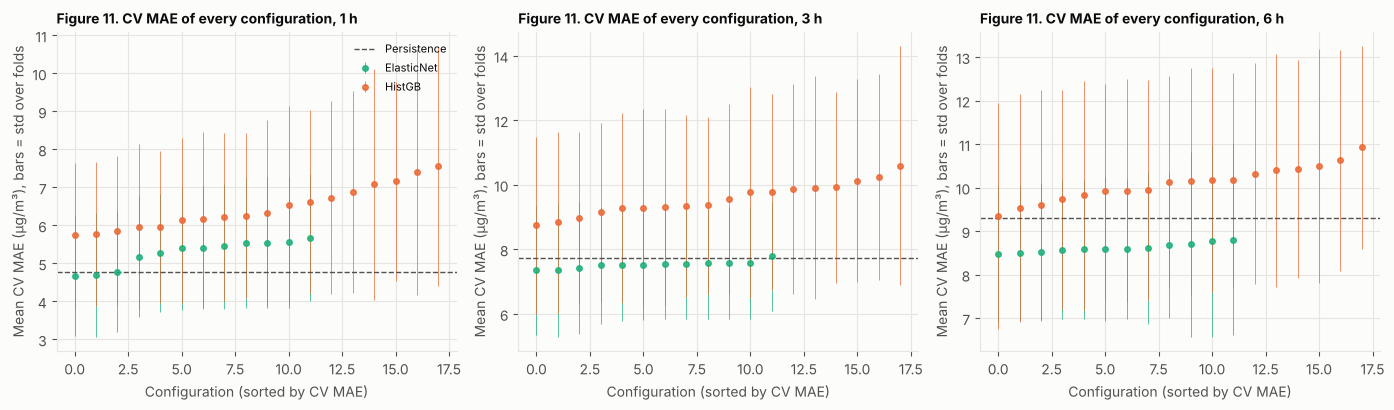

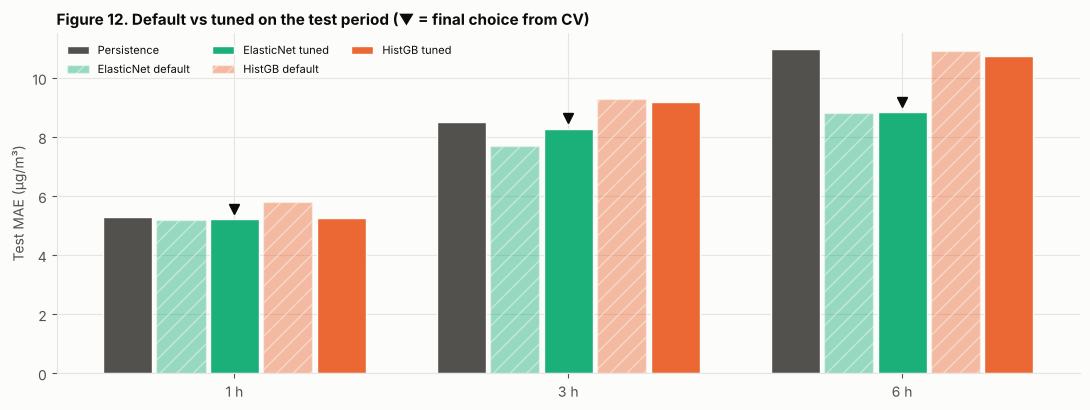

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
for ax, h in zip(axes, HORIZONS):
    for name in SHORT:
        q = CV_RES[(CV_RES["horizon_h"] == h) & (CV_RES["model"] == name)].sort_values("cv_MAE").reset_index(drop=True)
        ax.errorbar(q.index, q["cv_MAE"], yerr=q["cv_MAE_std"], fmt="o", ms=4, lw=0.6, color=MCOL[name], alpha=0.85, label=name)
        ax.scatter([], [], color=MCOL[name])
    ax.axhline(PERS_CV[h]["cv_MAE"], color=INK2, lw=1, ls="--", label="Persistence")
    ax.set_title(f"Figure 11. CV MAE of every configuration, {h} h", fontsize=10); ax.set_xlabel("Configuration (sorted by CV MAE)"); ax.set_ylabel("Mean CV MAE (µg/m³), bars = std over folds")
axes[0].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "fig11_tuning_search.png")

fig, ax = plt.subplots(figsize=(11, 4.2))
labs = ["Persistence"] + [f"{n} {k}" for n in SHORT for k in ("default", "tuned")]
w = 0.16
for j, lab in enumerate(labs):
    ys = [FT[(FT["horizon_h"] == h) & (FT["configuration"] == lab)]["MAE"].iloc[0] for h in HORIZONS]
    col = INK2 if lab == "Persistence" else MCOL[lab.split()[0]]
    bars = ax.bar(np.arange(3) + (j - 2) * w, ys, w * 0.92, color=col, alpha=0.45 if "default" in lab else 1.0, label=lab, hatch="//" if "default" in lab else None, edgecolor=SURF)
    for h_i, h in enumerate(HORIZONS):
        if FINAL_TEST[h]["label"] == lab: ax.plot(h_i + (j - 2) * w, ys[h_i] + 0.35, marker="v", color=INK, ms=7)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{h} h" for h in HORIZONS]); ax.set_ylabel("Test MAE (µg/m³)")
ax.set_title("Figure 12. Default vs tuned on the test period (▼ = final choice from CV)"); ax.legend(fontsize=8, ncol=3)
fig.tight_layout(); save_fig(fig, "fig12_default_vs_tuned_test.png")

## Section 15. Visualizations
Ten figures are saved to `outputs/figures/`. Colours follow a fixed order (blue, orange, aqua, magenta, violet), grey marks baselines and reference lines, and every multi-series chart carries a legend. Feature importance (figure 9) describes predictive association, **not causation**.

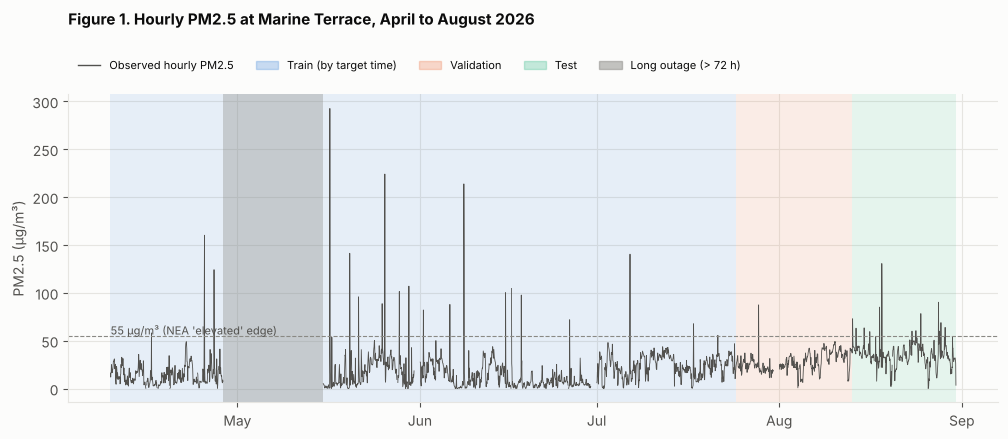

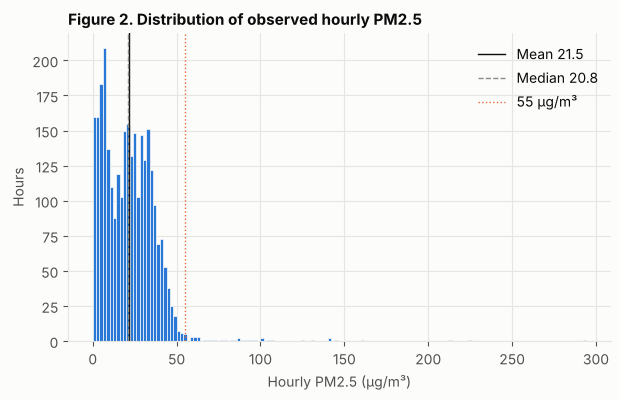

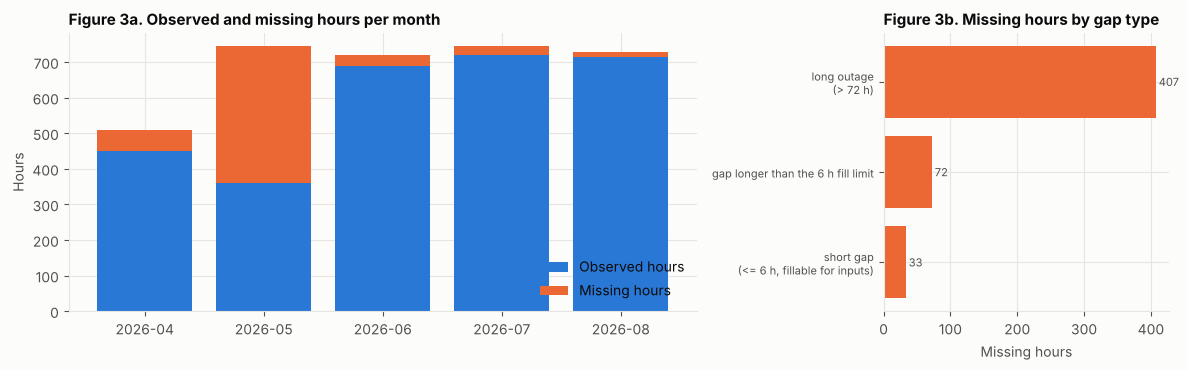

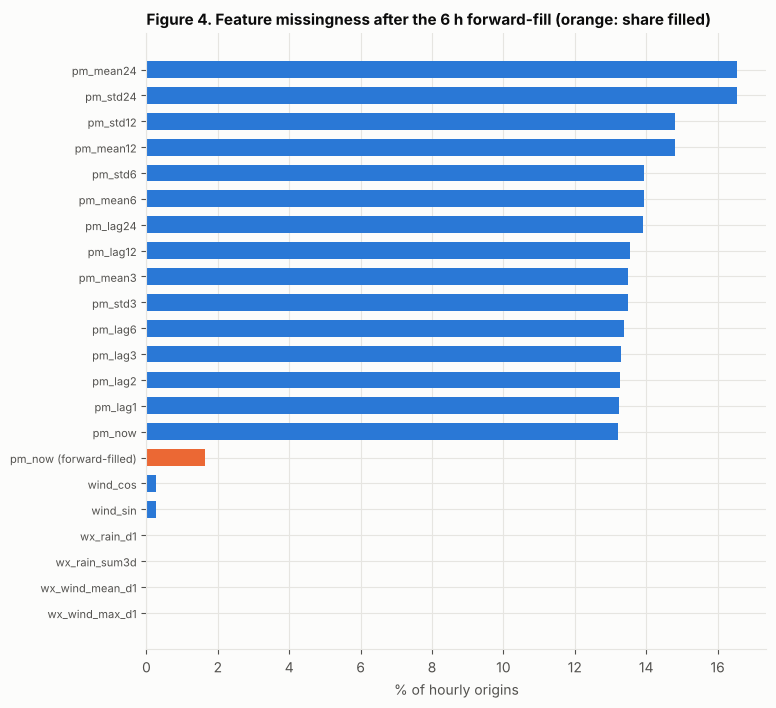

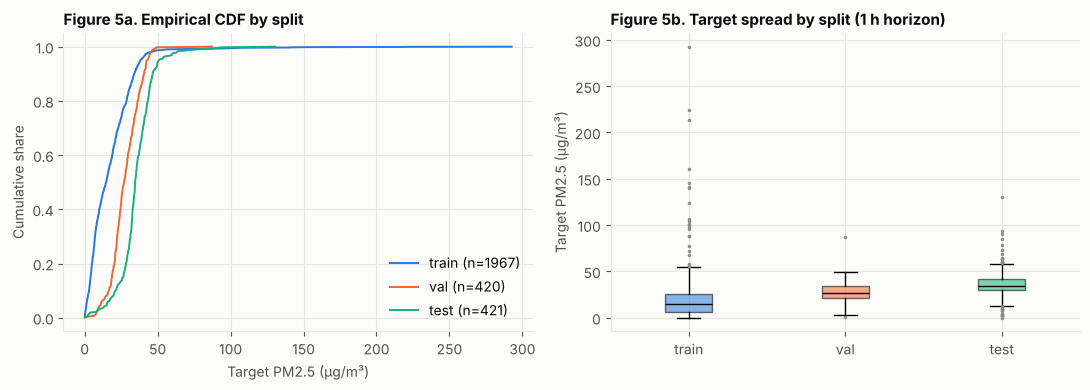

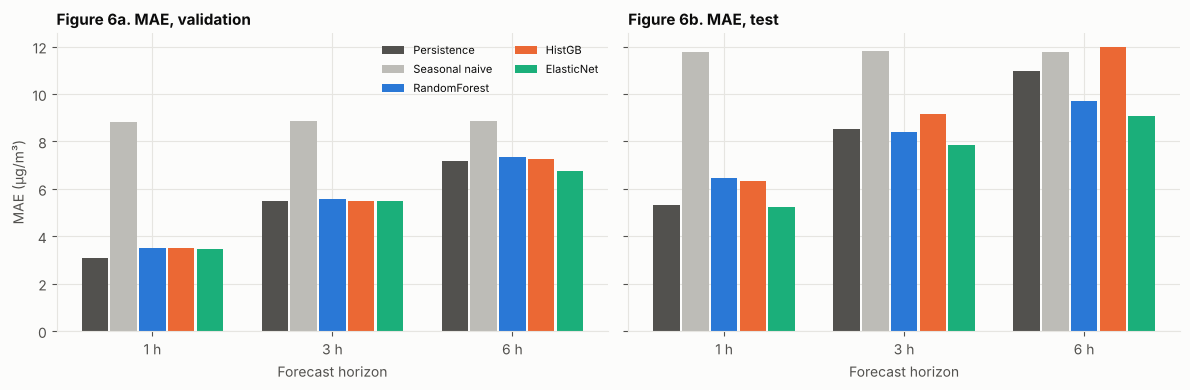

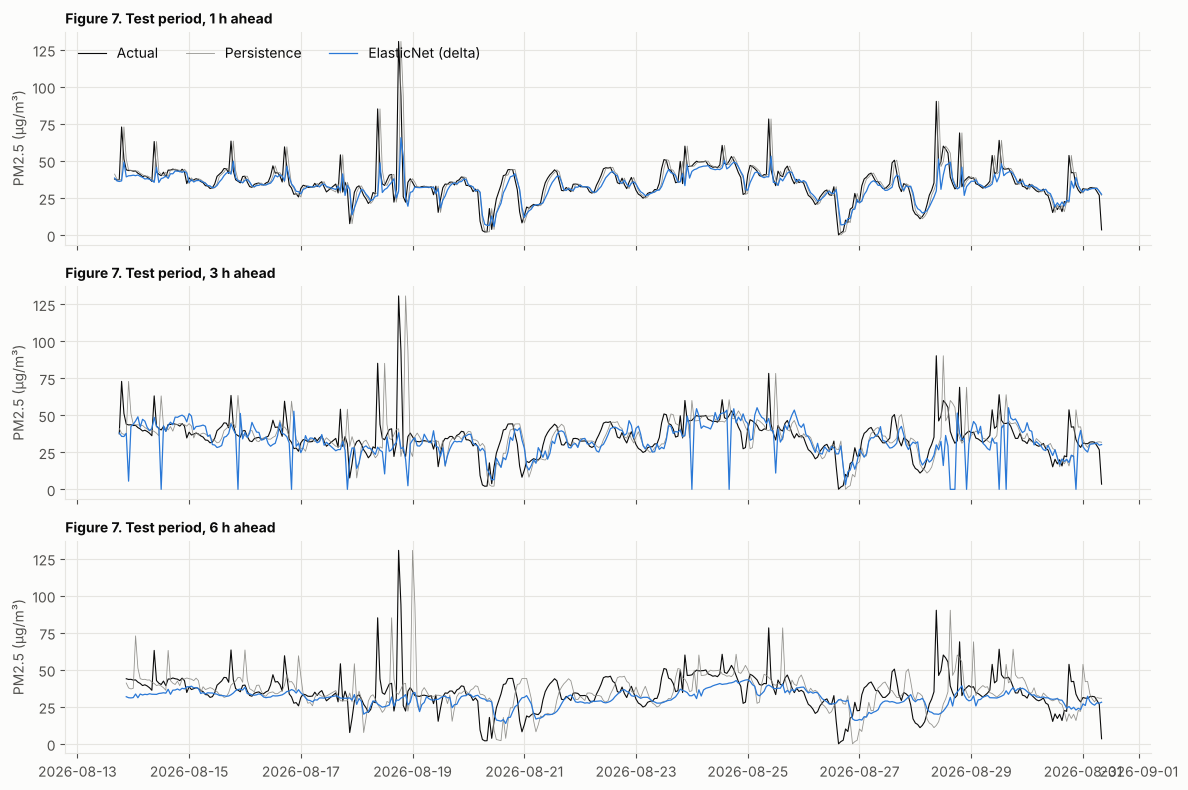

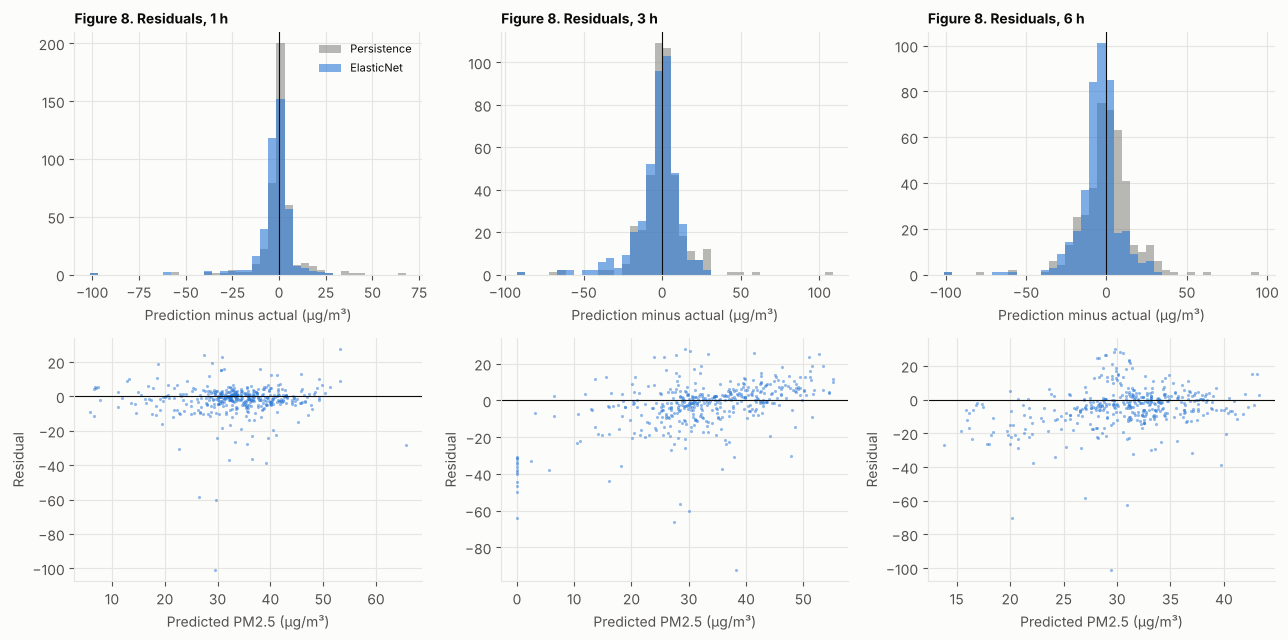

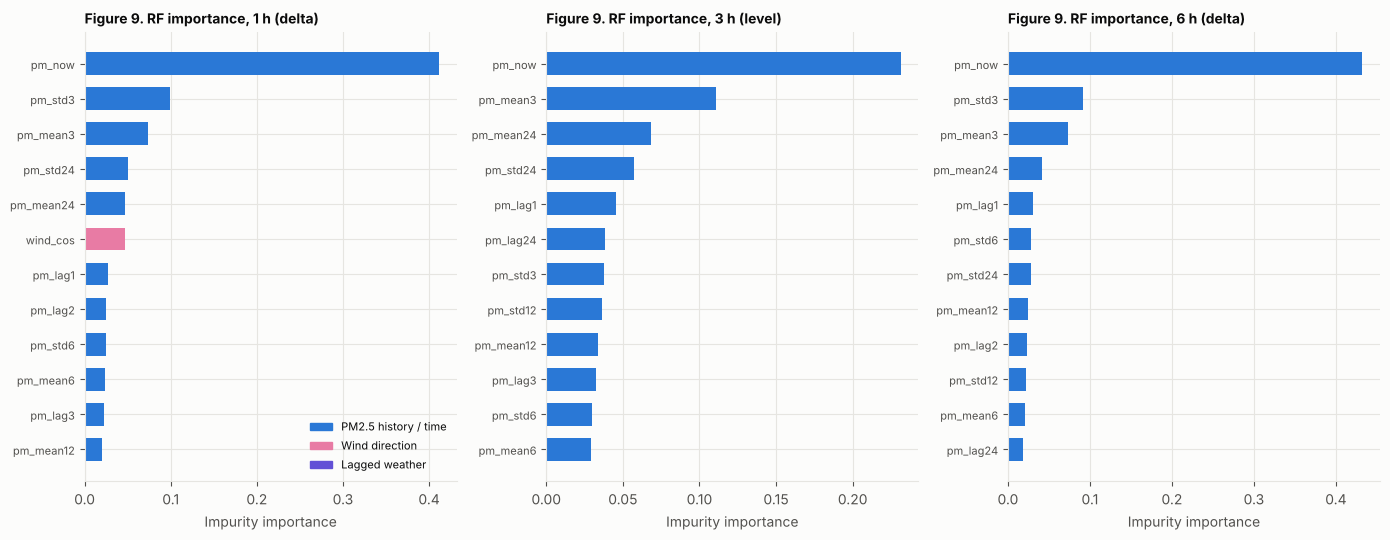

,horizon_h,top6_by_permutation_on_validation
0,1,"pm_now (0.18), pm_lag1 (0.17), pm_mean3 (0.08), pm_mean24 (0.07), pm_std24 (..."
1,3,"pm_now (1.34), pm_mean3 (0.13), pm_mean12 (0.10), wx_rain_sum3d (0.08), pm_m..."
2,6,"pm_now (1.74), wx_wind_max_d1 (0.25), pm_mean3 (0.23), pm_lag24 (0.10), pm_l..."


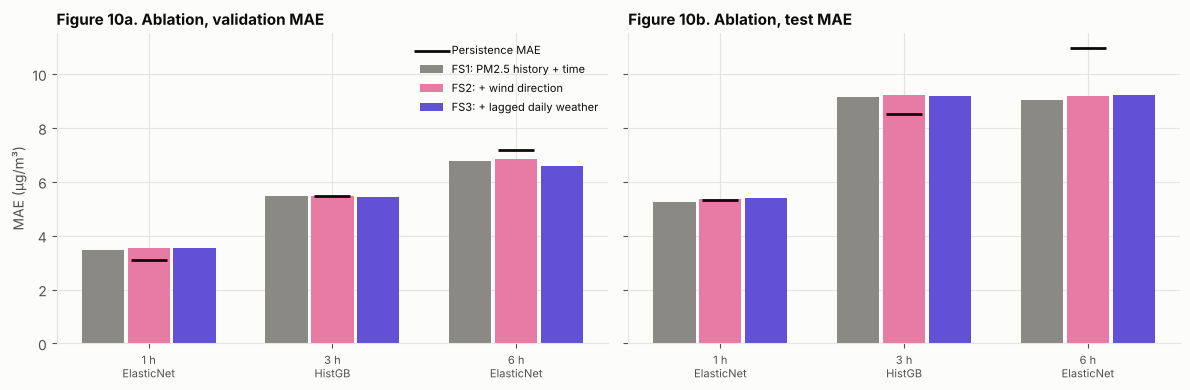

In [24]:
def span_shade(ax, a, b, color, alpha=0.10):
    ax.axvspan(a, b, color=color, alpha=alpha, lw=0)

# ---- Figure 1: time series
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pm_obs.index, pm_obs.values, color=INK2, lw=0.6, label="Observed hourly PM2.5")
t_start, t_end = pm_obs.index.min(), pm_obs.index.max()
span_shade(ax, t_start, B1, C_BLUE); span_shade(ax, B1, B2, C_ORANGE); span_shade(ax, B2, t_end, C_AQUA)
for _, g in gaps[gaps["hours"] > LONG_OUTAGE_H].iterrows():
    ax.axvspan(g["start"], g["end"], color=C_GREY, alpha=0.35, lw=0)
ax.axhline(NEA_ELEVATED, color=C_GREY, lw=0.8, ls="--")
ax.text(t_start, NEA_ELEVATED + 1.5, "55 µg/m³ (NEA 'elevated' edge)", color=INK2, fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[plt.Line2D([], [], color=INK2, lw=1, label="Observed hourly PM2.5"),
                   Patch(color=C_BLUE, alpha=.25, label="Train (by target time)"), Patch(color=C_ORANGE, alpha=.25, label="Validation"),
                   Patch(color=C_AQUA, alpha=.25, label="Test"), Patch(color=C_GREY, alpha=.5, label=f"Long outage (> {LONG_OUTAGE_H} h)")],
          ncol=5, loc="upper left", bbox_to_anchor=(0, 1.15), fontsize=8)
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("Figure 1. Hourly PM2.5 at Marine Terrace, April to August 2026", y=1.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.xaxis.set_major_locator(mdates.MonthLocator())
save_fig(fig, "fig01_pm25_time_series.png")

# ---- Figure 2: histogram
fig, ax = plt.subplots(figsize=(7, 4))
vals = pm_obs.dropna()
ax.hist(vals, bins=np.arange(0, vals.max() + 3, 2), color=C_BLUE, edgecolor=SURF, lw=0.5)
ax.axvline(vals.mean(), color=INK, lw=1, label=f"Mean {vals.mean():.1f}"); ax.axvline(vals.median(), color=C_GREY, lw=1, ls="--", label=f"Median {vals.median():.1f}")
ax.axvline(NEA_ELEVATED, color=C_ORANGE, lw=1, ls=":", label="55 µg/m³")
ax.set_xlabel("Hourly PM2.5 (µg/m³)"); ax.set_ylabel("Hours"); ax.set_title("Figure 2. Distribution of observed hourly PM2.5"); ax.legend()
save_fig(fig, "fig02_pm25_histogram.png")

# ---- Figure 3: missing hours and outages
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
miss_m = pm_obs.isna().groupby(pm_obs.index.strftime("%Y-%m")).sum()
tot_m = pm_obs.groupby(pm_obs.index.strftime("%Y-%m")).size()
a1.bar(miss_m.index, tot_m - miss_m, color=C_BLUE, label="Observed hours")
a1.bar(miss_m.index, miss_m, bottom=tot_m - miss_m, color=C_ORANGE, label="Missing hours")
a1.set_ylabel("Hours"); a1.set_title("Figure 3a. Observed and missing hours per month"); a1.legend(loc="lower right")
cat = gaps.groupby("category")["hours"].sum().sort_values()
a2.barh([c.replace(" (", "\n(") for c in cat.index], cat.values, color=C_ORANGE)
for i, v in enumerate(cat.values):
    a2.text(v, i, f" {v}", va="center", fontsize=8, color=INK2)
a2.set_xlabel("Missing hours"); a2.set_title("Figure 3b. Missing hours by gap type"); a2.tick_params(axis="y", labelsize=8)
fig.tight_layout(); save_fig(fig, "fig03_missing_and_outages.png")

# ---- Figure 4: feature missingness
all_feats = HIST + WIND + WEATHER
miss_pct = X_all[all_feats].isna().mean().mul(100)
imp_pct = pd.Series(100 * META["pm_now_imputed"].mean(), index=["pm_now (forward-filled)"])
mm = pd.concat([miss_pct, imp_pct]).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(mm.index, mm.values, color=[C_ORANGE if "filled" in i else C_BLUE for i in mm.index], height=0.65)
ax.set_xlabel("% of hourly origins"); ax.set_title("Figure 4. Feature missingness after the 6 h forward-fill (orange: share filled)")
ax.tick_params(axis="y", labelsize=8)
save_fig(fig, "fig04_feature_missingness.png")

# ---- Figure 5: distributions by split (horizon 1 h)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for sp in ["train", "val", "test"]:
    y = np.sort(DS[1].loc[DS[1]["split"] == sp, "target"].to_numpy())
    a1.plot(y, np.arange(1, len(y) + 1) / len(y), color=SPLIT_COL[sp], lw=1.4, label=f"{sp} (n={len(y)})")
a1.set_xlabel("Target PM2.5 (µg/m³)"); a1.set_ylabel("Cumulative share"); a1.set_title("Figure 5a. Empirical CDF by split"); a1.legend()
bp = a2.boxplot([DS[1].loc[DS[1]["split"] == sp, "target"] for sp in ["train", "val", "test"]], tick_labels=["train", "val", "test"], patch_artist=True,
                showfliers=True, flierprops=dict(marker=".", markersize=3, markeredgecolor=C_GREY), medianprops=dict(color=INK))
for patch, sp in zip(bp["boxes"], ["train", "val", "test"]):
    patch.set_facecolor(SPLIT_COL[sp]); patch.set_alpha(0.55)
a2.set_ylabel("Target PM2.5 (µg/m³)"); a2.set_title("Figure 5b. Target spread by split (1 h horizon)")
fig.tight_layout(); save_fig(fig, "fig05_split_distributions.png")

# ---- Figure 6: model comparison (validation and test MAE)
MCOL = {"Persistence": INK2, "Seasonal naive": "#bdbcb7", "RandomForest": C_BLUE, "HistGB": C_ORANGE, "ElasticNet": C_AQUA}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
order = ["Persistence", "Seasonal naive"] + MODELS
for ax, sp in zip(axes, ["val", "test"]):
    w = 0.16
    for j, nm in enumerate(order):
        ys = []
        for h in HORIZONS:
            q = M[(M["horizon_h"] == h) & (M["split"] == sp) & (M["model"] == nm) & (M["feature_set"].isin(["-", "FS1"]))]
            if nm in MODELS: q = q[q["mode"] == BEST_MODE[(h, nm)]]
            ys.append(q["MAE"].iloc[0])
        ax.bar(np.arange(3) + (j - 2) * w, ys, w * 0.92, color=MCOL[nm], label=nm)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{h} h" for h in HORIZONS]); ax.set_title(f"Figure 6{'a' if sp == 'val' else 'b'}. MAE, {'validation' if sp == 'val' else 'test'}")
    ax.set_xlabel("Forecast horizon")
axes[0].set_ylabel("MAE (µg/m³)"); axes[0].legend(ncol=2, fontsize=8)
fig.tight_layout(); save_fig(fig, "fig06_model_comparison.png")

# ---- Figure 7: actual vs predicted (test)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, h in zip(axes, HORIZONS):
    name, mode = SEL[h]; T = DS[h][DS[h]["split"] == "test"]
    tt_ = T["target_time"]
    ax.plot(tt_, T["target"], color=INK, lw=0.8, label="Actual")
    ax.plot(tt_, T["persistence"], color=C_GREY, lw=0.6, alpha=0.9, label="Persistence")
    ax.plot(tt_, PRED[(h, "FS1", name, mode)]["test"], color=C_BLUE, lw=0.9, label=f"{name} ({mode})")
    ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title(f"Figure 7. Test period, {h} h ahead", fontsize=10)
    if h == 1: ax.legend(ncol=3, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig07_actual_vs_predicted.png")

# ---- Figure 8: residuals
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for j, h in enumerate(HORIZONS):
    name, mode = SEL[h]; T = DS[h][DS[h]["split"] == "test"]
    pr = PRED[(h, "FS1", name, mode)]["test"]
    res_m, res_p = pr - T["target"], T["persistence"] - T["target"]
    bins = np.linspace(min(res_m.min(), res_p.min()), max(res_m.max(), res_p.max()), 40)
    axes[0, j].hist(res_p, bins=bins, color=C_GREY, alpha=0.6, label="Persistence")
    axes[0, j].hist(res_m, bins=bins, color=C_BLUE, alpha=0.6, label=f"{name}")
    axes[0, j].axvline(0, color=INK, lw=0.8); axes[0, j].set_title(f"Figure 8. Residuals, {h} h", fontsize=10); axes[0, j].set_xlabel("Prediction minus actual (µg/m³)")
    axes[1, j].scatter(pr, res_m, s=5, color=C_BLUE, alpha=0.5, lw=0); axes[1, j].axhline(0, color=INK, lw=0.8)
    axes[1, j].set_xlabel("Predicted PM2.5 (µg/m³)"); axes[1, j].set_ylabel("Residual")
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "fig08_residuals.png")

# ---- Figure 9: random-forest importance (impurity), FS3
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
RF_IMP = {}
for ax, h in zip(axes, HORIZONS):
    mode = BEST_MODE[(h, "RandomForest")]
    pipe = PIPES[(h, "FS3", "RandomForest", mode)]
    imp = pd.Series(pipe.named_steps["m"].feature_importances_, index=FEATURE_SETS["FS3"]).sort_values(ascending=False)
    RF_IMP[h] = imp
    top = imp.head(12)[::-1]
    ax.barh(top.index, top.values, color=[C_VIOLET if f in WEATHER else C_MAG if f in WIND else C_BLUE for f in top.index], height=0.65)
    ax.set_title(f"Figure 9. RF importance, {h} h ({mode})", fontsize=10); ax.set_xlabel("Impurity importance"); ax.tick_params(axis="y", labelsize=8)
axes[0].legend(handles=[Patch(color=C_BLUE, label="PM2.5 history / time"), Patch(color=C_MAG, label="Wind direction"), Patch(color=C_VIOLET, label="Lagged weather")],
               loc="lower right", fontsize=8)
fig.tight_layout(); save_fig(fig, "fig09_rf_feature_importance.png")

# permutation importance on validation (a check on the impurity ranking; association, not causation)
perm_rows = []
for h in HORIZONS:
    mode = BEST_MODE[(h, "RandomForest")]
    pipe = PIPES[(h, "FS3", "RandomForest", mode)]
    V = DS[h][DS[h]["split"] == "val"]
    yv = V["target"] - V["persistence"] if mode == "delta" else V["target"]
    pi = permutation_importance(pipe, V[FEATURE_SETS["FS3"]], yv, n_repeats=10, random_state=SEED, scoring="neg_mean_absolute_error")
    s = pd.Series(pi.importances_mean, index=FEATURE_SETS["FS3"]).sort_values(ascending=False).head(6)
    perm_rows.append({"horizon_h": h, "top6_by_permutation_on_validation": ", ".join(f"{k} ({v:.2f})" for k, v in s.items())})
display(pd.DataFrame(perm_rows))

# ---- Figure 10: ablation
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sp in zip(axes, ["val", "test"]):
    w = 0.25
    for j, fs in enumerate(FEATURE_SETS):
        ys = [ablation[(ablation["horizon_h"] == h) & (ablation["fs"] == fs) & (ablation["split"] == sp)]["MAE"].iloc[0] for h in HORIZONS]
        ax.bar(np.arange(3) + (j - 1) * w, ys, w * 0.92, color=FS_COL[fs], label=FS_LABEL[fs])
    pers = [M[(M["horizon_h"] == h) & (M["split"] == sp) & (M["model"] == "Persistence")]["MAE"].iloc[0] for h in HORIZONS]
    ax.scatter(np.arange(3), pers, marker="_", s=700, color=INK, lw=2, zorder=3, label="Persistence MAE")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{h} h\n{SEL[h][0]}" for h in HORIZONS], fontsize=8)
    ax.set_title(f"Figure 10{'a' if sp == 'val' else 'b'}. Ablation, {'validation' if sp == 'val' else 'test'} MAE")
axes[0].set_ylabel("MAE (µg/m³)"); axes[0].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "fig10_feature_ablation.png")

### Section 15b. Model interpretation
The final models are tuned ElasticNet pipelines that predict the **change from the latest reading** (`delta` target), on standardised features. A coefficient therefore says how many µg/m³ the *forecast change* moves per one standard deviation of a feature, holding the others fixed. Permutation importance (computed on the **validation** period with the same configuration fitted on the training rows) shows how much validation MAE rises when one feature is shuffled. Both describe **predictive association, not cause and effect**: for instance, a wind-direction coefficient does not mean wind direction changes PM2.5 at this sensor.

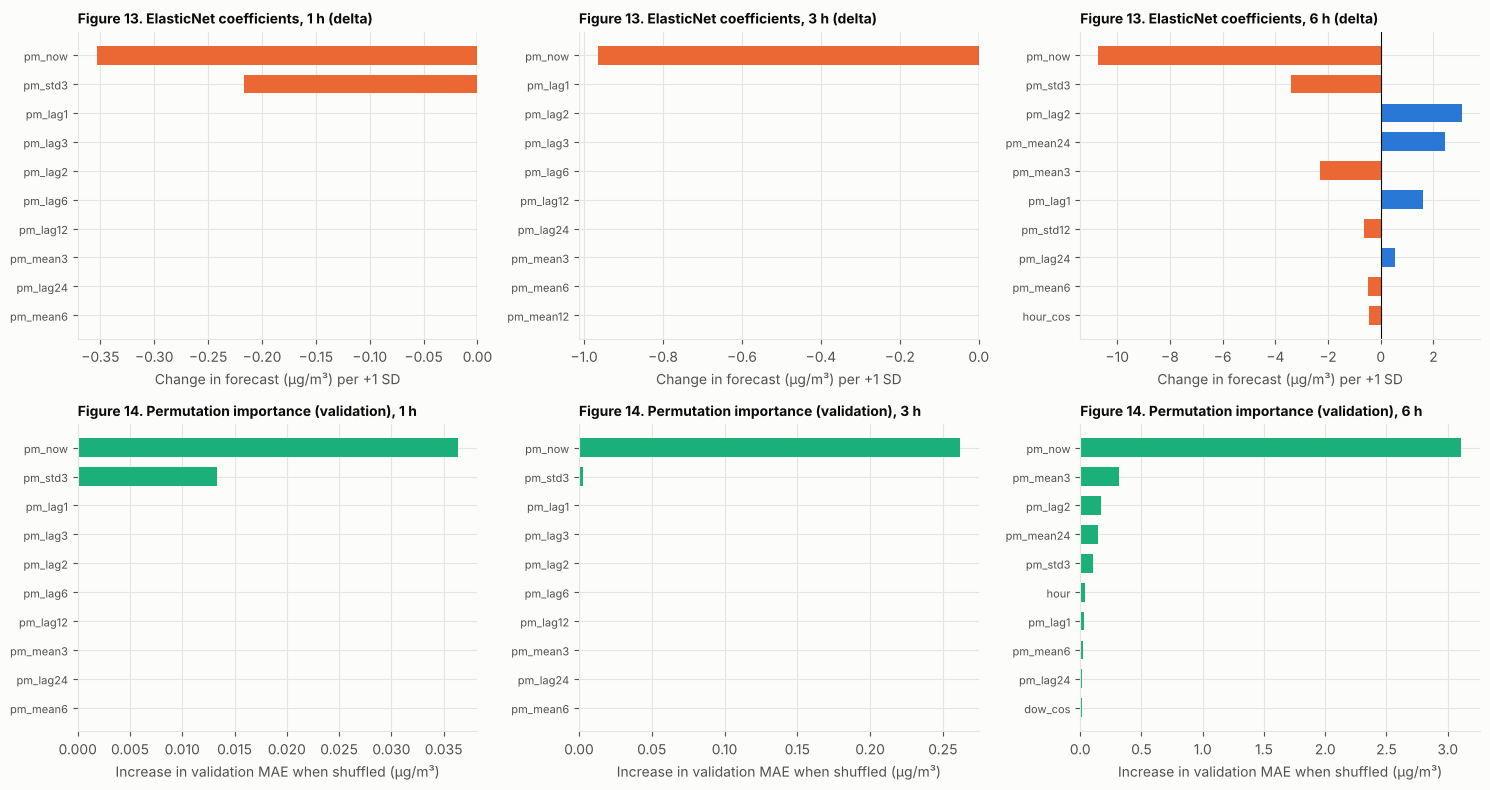

Top-3 features by permutation importance: {1: ['pm_now', 'pm_std3', 'pm_lag1'], 3: ['pm_now', 'pm_std3', 'pm_lag1'], 6: ['pm_now', 'pm_mean3', 'pm_lag2']}


In [25]:
if "ElasticNet" not in SHORT:
    print("ElasticNet was not shortlisted; interpretation skipped.")
else:
    cols = FEATURE_SETS["FS1"]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    coef_rows, perm_rows2 = [], []
    for j, h in enumerate(HORIZONS):
        mode, params = BEST_MODE[(h, "ElasticNet")], BEST_CFG[(h, "ElasticNet")][0]
        pipe, _ = fit_dev_predict(h, "ElasticNet", mode, params)                  # coefficients from the development-set refit
        coef = pd.Series(pipe.named_steps["m"].coef_, index=cols)
        top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)[::-1]
        axes[0, j].barh(top.index, top.values, color=[C_BLUE if v_ >= 0 else C_ORANGE for v_ in top.values], height=0.65)
        axes[0, j].axvline(0, color=INK, lw=0.8)
        axes[0, j].set_title(f"Figure 13. ElasticNet coefficients, {h} h ({mode})", fontsize=10); axes[0, j].tick_params(axis="y", labelsize=8)
        axes[0, j].set_xlabel("Change in forecast (µg/m³) per +1 SD")
        for f_, v_ in coef.items(): coef_rows.append({"horizon_h": h, "feature": f_, "coefficient": v_, "mode": mode, **{f"param_{k_}": p_ for k_, p_ in params.items()}})
        D = DS[h]; tr, va = D[D["split"] == "train"], D[D["split"] == "val"]
        y_tr = tr["target"] - tr["persistence"] if mode == "delta" else tr["target"]
        y_va = va["target"] - va["persistence"] if mode == "delta" else va["target"]
        pipe_tr = make_pipe("ElasticNet", params).fit(tr[cols], y_tr)
        pi = permutation_importance(pipe_tr, va[cols], y_va, n_repeats=15, random_state=SEED, scoring="neg_mean_absolute_error")
        pser = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
        t2 = pser.head(10)[::-1]
        axes[1, j].barh(t2.index, t2.values, color=C_AQUA, height=0.65)
        axes[1, j].set_title(f"Figure 14. Permutation importance (validation), {h} h", fontsize=10); axes[1, j].tick_params(axis="y", labelsize=8)
        axes[1, j].set_xlabel("Increase in validation MAE when shuffled (µg/m³)")
        for f_, v_ in pser.items(): perm_rows2.append({"horizon_h": h, "feature": f_, "perm_importance_MAE": v_})
    fig.tight_layout(); save_fig(fig, "fig13_14_model_interpretation.png")
    COEF_TBL, PERM_TBL = pd.DataFrame(coef_rows), pd.DataFrame(perm_rows2)
    COEF_TBL.to_csv(MET_DIR / "elasticnet_coefficients.csv", index=False); PERM_TBL.to_csv(MET_DIR / "elasticnet_permutation_importance.csv", index=False)
    TOPF = {h: PERM_TBL[PERM_TBL["horizon_h"] == h].sort_values("perm_importance_MAE", ascending=False).head(3)["feature"].tolist() for h in HORIZONS}
    print("Top-3 features by permutation importance:", TOPF)

## Section 16. Interpretation
The answers below are **generated from the computed results**, so they stay consistent if the data or settings change. They describe this sensor, this location and April to August 2026 only.

In [26]:
from IPython.display import Markdown
def g(h, sp, model=None, fs="FS1", mode=None):
    q = M[(M["horizon_h"] == h) & (M["split"] == sp)]
    if model in ("Persistence", "Seasonal naive"): return q[q["model"] == model].iloc[0]
    return q[(q["model"] == model) & (q["feature_set"] == fs) & (q["mode"] == mode)].iloc[0]

L = []
# Q1 / Q2
L.append("**1. Does any model beat persistence on validation MAE?**")
for h in HORIZONS:
    p = g(h, "val", "Persistence")["MAE"]
    best = {m: g(h, "val", m, "FS1", BEST_MODE[(h, m)])["MAE"] for m in MODELS}
    wins = [m for m, v in best.items() if v < p]
    L.append(f"- {h} h: persistence {p:.2f}; " + ", ".join(f"{m} {v:.2f}" for m, v in best.items()) + (f". Better than persistence: {', '.join(wins)}." if wins else ". None beats persistence."))
L.append("\n**2. Does the improvement persist on the test period?** (final model per horizon, chosen by cross-validation on train + validation, then scored once on test)")
for h in HORIZONS:
    f = FINAL_TEST[h]
    if f["label"] == "Persistence":
        L.append(f"- {h} h: no tuned or default model beat persistence in cross-validation, so persistence is the final model (test MAE {f['pers_MAE']:.2f}).")
        best = FT[(FT['horizon_h'] == h) & (~FT['configuration'].isin(['Persistence', 'Seasonal naive']))].sort_values('MAE').iloc[0]
        L.append(f"  - For reference, the best learned configuration on test would have been {best['configuration']} with MAE {best['MAE']:.2f} (skill {best['skill_vs_persistence']:+.1%}); it was not selected, so this is not a result.")
    else:
        verdict = "improves on" if f["MAE"] < f["pers_MAE"] else "does not improve on"
        L.append(f"- {h} h: {f['label']} test MAE {f['MAE']:.2f} vs persistence {f['pers_MAE']:.2f}; it {verdict} persistence, skill {f['skill']:+.1%} (95 % block-bootstrap interval {f['skill_lo']:+.1%} to {f['skill_hi']:+.1%}).")
# Q3
L.append("\n**3. How does performance change from 1 to 6 hours ahead?**")
L.append("- Test MAE, persistence: " + " -> ".join(f"{FINAL_TEST[h]['pers_MAE']:.2f}" for h in HORIZONS) + " µg/m³ for 1, 3, 6 h; final model: " + " -> ".join(f"{FINAL_TEST[h]['MAE']:.2f}" for h in HORIZONS) + "; final-model R²: " + " -> ".join(f"{FINAL_TEST[h]['R2']:.2f}" for h in HORIZONS) + ". Errors grow with the horizon because the most recent value says less about the future.")
# Q4
L.append("\n**4. Do wind and lagged weather improve performance?**")
for h in HORIZONS:
    a = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "test")].set_index("fs")
    v = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "val")].set_index("fs")
    def fmt(fs):
        ci = f", interval {a.loc[fs, 'change_ci_lo']:+.2f} to {a.loc[fs, 'change_ci_hi']:+.2f}" if pd.notna(a.loc[fs, "change_ci_lo"]) else ""
        return f"{FS_LABEL[fs].split(': ')[1]}: test change {a.loc[fs, 'MAE_change_vs_FS1']:+.2f}{ci}; validation change {v.loc[fs, 'MAE_change_vs_FS1']:+.2f}"
    L.append(f"- {h} h ({SEL[h][0]}): FS1 test MAE {a.loc['FS1', 'MAE']:.2f}; " + "; ".join(fmt(f) for f in ["FS2", "FS3"]) + " (MAE change vs FS1; negative = better).")
L.append("- A gain counts as evidence only if it is negative on validation *and* test and its interval excludes zero; otherwise the features are not shown to help in this dataset.")
for h in HORIZONS:
    a = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "test")].set_index("fs")
    v = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "val")].set_index("fs")
    for fs in ["FS2", "FS3"]:
        ok = (a.loc[fs, "MAE_change_vs_FS1"] < 0) and (v.loc[fs, "MAE_change_vs_FS1"] < 0) and (a.loc[fs, "change_ci_hi"] < 0)
        L.append(f"  - {h} h, {FS_LABEL[fs].split(': ')[1]}: " + ("meets the evidence rule." if ok else "does not meet the evidence rule."))
# Q5
L.append("\n**5. Are the train, validation and test distributions different?**")
sp_ = split_summary[(split_summary["horizon_h"] == 1) & split_summary["split"].isin(["train", "val", "test"])].set_index("split")
L.append("- Mean / median / 95th pct / max (1 h targets): " + "; ".join(f"{s}: {sp_.loc[s, 'target_mean']:.1f} / {sp_.loc[s, 'target_median']:.1f} / {sp_.loc[s, 'target_q95']:.1f} / {sp_.loc[s, 'target_max']:.0f}" for s in ["train", "val", "test"]) + ".")
ks = {f"{a} vs {b}": stats.ks_2samp(DS[1].loc[DS[1]['split'] == a, 'target'], DS[1].loc[DS[1]['split'] == b, 'target']) for a, b in [("train", "val"), ("train", "test")]}
L.append("- Kolmogorov-Smirnov tests: " + "; ".join(f"{k} D = {v.statistic:.2f}" for k, v in ks.items()) + " (p-values are not reliable for autocorrelated data; D is shown as an effect size). Larger D means a stronger shift in level, which makes the level target harder to predict out of period.")
# Q6
L.append("\n**6. How much uncertainty is associated with the evaluation?**")
for h in HORIZONS:
    b = boot[(boot["horizon_h"] == h) & (boot["split"] == "test") & (boot["quantity"] == "model_MAE")]
    if len(b):
        L.append(f"- {h} h: model test MAE {b.iloc[0]['estimate']:.2f} (95 % interval {b.iloc[0]['ci_lo_95']:.2f} to {b.iloc[0]['ci_hi_95']:.2f}, n = {int(b.iloc[0]['n'])}).")
L.append("- The test period is a single contiguous stretch with few independent episodes, so these intervals are approximate and probably optimistic.")
# Q7
L.append("\n**7. Does the model perform poorly during high-PM2.5 episodes?**")
for h in HORIZONS:
    T = DS[h][DS[h]["split"] == "test"]; name, mode = SEL[h]
    hi = T["target"] > NEA_ELEVATED
    if hi.sum() == 0:
        L.append(f"- {h} h: no test target above {NEA_ELEVATED} µg/m³."); continue
    ep = int(((T.loc[hi, "target_time"].diff() > pd.Timedelta(hours=6)) | T.loc[hi, "target_time"].diff().isna()).sum())
    e_m = np.abs(PRED[(h, "FS1", name, mode)]["test"][hi] - T.loc[hi, "target"]).mean()
    e_p = np.abs(T.loc[hi, "persistence"] - T.loc[hi, "target"]).mean()
    e_lo = np.abs(PRED[(h, "FS1", name, mode)]["test"][~hi] - T.loc[~hi, "target"]).mean()
    L.append(f"- {h} h: {int(hi.sum())} test hours above {NEA_ELEVATED} µg/m³ in {ep} episode(s); model MAE {e_m:.1f} there vs {e_lo:.1f} on the other hours; persistence MAE {e_p:.1f} on those hours.")
L.append("- With so few high hours and episodes, this analysis cannot show that the model detects spikes reliably, and no such claim is made.")
L.append("\n**Bottom line.** Read the numbers above first: if persistence is as good as or better than the learned models, that is a valid result, not a failure. This notebook tests short-horizon forecasting at one sensor; it does not validate a 24 to 48 hour haze-warning system.")
display(Markdown("\n".join(L)))
INTERP_TEXT = "\n".join(L)

**1. Does any model beat persistence on validation MAE?**
- 1 h: persistence 3.10; RandomForest 3.49, HistGB 3.51, ElasticNet 3.48. None beats persistence.
- 3 h: persistence 5.48; RandomForest 5.58, HistGB 5.47, ElasticNet 5.48. Better than persistence: HistGB, ElasticNet.
- 6 h: persistence 7.19; RandomForest 7.34, HistGB 7.24, ElasticNet 6.76. Better than persistence: ElasticNet.

**2. Does the improvement persist on the test period?** (final model per horizon, chosen by cross-validation on train + validation, then scored once on test)
- 1 h: ElasticNet tuned test MAE 5.22 vs persistence 5.31; it improves on persistence, skill +1.6% (95 % block-bootstrap interval +0.8% to +2.2%).
- 3 h: ElasticNet tuned test MAE 8.28 vs persistence 8.52; it improves on persistence, skill +2.8% (95 % block-bootstrap interval +1.9% to +3.4%).
- 6 h: ElasticNet tuned test MAE 8.84 vs persistence 10.97; it improves on persistence, skill +19.5% (95 % block-bootstrap interval +11.9% to +26.8%).

**3. How does performance change from 1 to 6 hours ahead?**
- Test MAE, persistence: 5.31 -> 8.52 -> 10.97 µg/m³ for 1, 3, 6 h; final model: 5.22 -> 8.28 -> 8.84; final-model R²: 0.28 -> -0.20 -> -0.12. Errors grow with the horizon because the most recent value says less about the future.

**4. Do wind and lagged weather improve performance?**
- 1 h (ElasticNet): FS1 test MAE 5.25; + wind direction: test change +0.11, interval +0.06 to +0.15; validation change +0.05; + lagged daily weather: test change +0.14, interval +0.05 to +0.22; validation change +0.06 (MAE change vs FS1; negative = better).
- 3 h (HistGB): FS1 test MAE 9.17; + wind direction: test change +0.05, interval -0.02 to +0.12; validation change +0.01; + lagged daily weather: test change +0.02, interval -0.19 to +0.25; validation change -0.05 (MAE change vs FS1; negative = better).
- 6 h (ElasticNet): FS1 test MAE 9.06; + wind direction: test change +0.12, interval +0.05 to +0.20; validation change +0.09; + lagged daily weather: test change +0.17, interval +0.01 to +0.28; validation change -0.18 (MAE change vs FS1; negative = better).
- A gain counts as evidence only if it is negative on validation *and* test and its interval excludes zero; otherwise the features are not shown to help in this dataset.
  - 1 h, + wind direction: does not meet the evidence rule.
  - 1 h, + lagged daily weather: does not meet the evidence rule.
  - 3 h, + wind direction: does not meet the evidence rule.
  - 3 h, + lagged daily weather: does not meet the evidence rule.
  - 6 h, + wind direction: does not meet the evidence rule.
  - 6 h, + lagged daily weather: does not meet the evidence rule.

**5. Are the train, validation and test distributions different?**
- Mean / median / 95th pct / max (1 h targets): train: 17.5 / 14.7 / 38.1 / 293; val: 27.8 / 27.1 / 42.7 / 87; test: 35.4 / 34.6 / 50.9 / 131.
- Kolmogorov-Smirnov tests: train vs val D = 0.46; train vs test D = 0.62 (p-values are not reliable for autocorrelated data; D is shown as an effect size). Larger D means a stronger shift in level, which makes the level target harder to predict out of period.

**6. How much uncertainty is associated with the evaluation?**
- 1 h: model test MAE 5.25 (95 % interval 4.19 to 6.50, n = 421).
- 3 h: model test MAE 9.17 (95 % interval 7.67 to 10.78, n = 419).
- 6 h: model test MAE 9.06 (95 % interval 7.45 to 10.92, n = 416).
- The test period is a single contiguous stretch with few independent episodes, so these intervals are approximate and probably optimistic.

**7. Does the model perform poorly during high-PM2.5 episodes?**
- 1 h: 16 test hours above 55 µg/m³ in 11 episode(s); model MAE 33.6 there vs 4.1 on the other hours; persistence MAE 31.6 on those hours.
- 3 h: 16 test hours above 55 µg/m³ in 11 episode(s); model MAE 38.6 there vs 8.0 on the other hours; persistence MAE 34.4 on those hours.
- 6 h: 15 test hours above 55 µg/m³ in 10 episode(s); model MAE 41.7 there vs 7.8 on the other hours; persistence MAE 36.1 on those hours.
- With so few high hours and episodes, this analysis cannot show that the model detects spikes reliably, and no such claim is made.

**Bottom line.** Read the numbers above first: if persistence is as good as or better than the learned models, that is a valid result, not a failure. This notebook tests short-horizon forecasting at one sensor; it does not validate a 24 to 48 hour haze-warning system.

### Section 16c. Findings, actionable insights and business implications
Each row connects a **finding** to its **evidence**, a **specific action** a stakeholder could consider, the **implication** for planning, and the **limitation**. All numbers are computed from the results above.

In [27]:
fin_ = {h: FINAL_TEST[h] for h in HORIZONS}
# evidence on external features (initial protocol: same model, FS1 vs FS2 / FS3)
ev = []
for h in HORIZONS:
    a_ = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "test")].set_index("fs"); v_ = ablation[(ablation["horizon_h"] == h) & (ablation["split"] == "val")].set_index("fs")
    for fs in ["FS2", "FS3"]:
        if (a_.loc[fs, "MAE_change_vs_FS1"] < 0) and (v_.loc[fs, "MAE_change_vs_FS1"] < 0) and (a_.loc[fs, "change_ci_hi"] < 0): ev.append(f"{h} h {FS_LABEL[fs].split(': ')[1]}")
ev_txt = ("meets the evidence rule (lower MAE on validation and test, interval excludes zero) only for: " + "; ".join(ev)) if ev else "never meets the evidence rule"
# error on high-PM hours with the final models
hi_stats = []
for h in HORIZONS:
    T = DS[h][DS[h]["split"] == "test"]; lab = FINAL_TEST[h]["label"]
    p = TEST_PRED[h][lab][1]; hi = (T["target"] > NEA_ELEVATED).to_numpy()
    if hi.sum() > 0: hi_stats.append((h, int(hi.sum()), np.abs(p - T["target"].to_numpy())[hi].mean(), np.abs(p - T["target"].to_numpy())[~hi].mean()))
hi_txt = "; ".join(f"{h} h: {n} hours, MAE {e1:.1f} vs {e0:.1f} on other hours" for h, n, e1, e0 in hi_stats)
tr_mean, te_mean = split_summary[(split_summary["horizon_h"] == 1) & (split_summary["split"] == "train")]["target_mean"].iloc[0], split_summary[(split_summary["horizon_h"] == 1) & (split_summary["split"] == "test")]["target_mean"].iloc[0]
sk = lambda h: f"{fin_[h]['skill']:+.1%} (interval {fin_[h]['skill_lo']:+.1%} to {fin_[h]['skill_hi']:+.1%})"

FINDINGS = pd.DataFrame([
 {"#": "F1", "Finding": "The latest reading is an extremely strong forecast for the next 1 to 3 hours; the learned models add very little there.",
  "Evidence": f"Autocorrelation {EDA_FACTS['acf1']:.2f} at 1 h. Final-model MAE skill vs persistence on test: 1 h {sk(1)}, 3 h {sk(3)}. On validation no model beats persistence at 1 h.",
  "Actionable insight": "For planning within about 3 hours, use the latest reading (persistence) as the forecast; do not spend effort deploying a model for this range.",
  "Business implication": "Zero modelling cost and no pipeline risk for short-range outlooks; effort is better spent on sensor uptime.",
  "Limitation": "One sensor, a few weeks of test data, small gains with approximate intervals."},
 {"#": "F2", "Finding": "At 6 hours ahead a regularised linear model that predicts the change from the latest reading clearly improves on persistence.",
  "Evidence": f"6 h test MAE {fin_[6]['MAE']:.2f} vs persistence {fin_[6]['pers_MAE']:.2f}; skill {sk(6)}. Chosen by cross-validation before test.",
  "Actionable insight": "Use the 6 h model as a decision aid for next-shift planning (for example scheduling outdoor work), always shown next to the latest reading.",
  "Business implication": "The only horizon where analytics adds measurable planning value in this data.",
  "Limitation": f"Test R² is {fin_[6]['R2']:.2f} (negative), so level errors remain large; the test period is shifted upward (mean {te_mean:.1f} vs {tr_mean:.1f} in training)."},
 {"#": "F3", "Finding": "Wind direction and lagged daily weather give little dependable benefit.",
  "Evidence": f"In the ablation, adding wind or weather {ev_txt}. EDA: raw wind-sector medians differ by {EDA_FACTS['sector_range']:.1f} µg/m³, but this is confounded with time of year and does not carry over once PM2.5 history is known; lagged-rain correlations are small.",
  "Actionable insight": "Do not build a data feed for these two inputs on the strength of this study; test hourly wind speed and satellite or hotspot data before investing.",
  "Business implication": "Avoids integration cost for a feature set that has not shown value.",
  "Limitation": "Daily weather comes from another station; the wind station is unknown; only April to August is covered."},
 {"#": "F4", "Finding": "Forecast errors are far larger when PM2.5 is high, and there are too few such hours to judge.",
  "Evidence": f"Test hours above {NEA_ELEVATED} µg/m³ with the final models: {hi_txt}.",
  "Actionable insight": "Do not use these forecasts to trigger health or operational alerts; keep official alerts and human judgement for high-pollution periods.",
  "Business implication": "Limits the tool to routine planning; avoids false reassurance during pollution episodes.",
  "Limitation": "Very few high hours and episodes; the October haze season is not in the data."},
 {"#": "F5", "Finding": "PM2.5 levels drifted upward from training to test, so a model trained once will go stale.",
  "Evidence": f"Mean target {tr_mean:.1f} µg/m³ in training vs {te_mean:.1f} in test; the test-period R² is negative at 3 h and 6 h.",
  "Actionable insight": "Retrain on a rolling window (for example monthly) and track MAE against persistence each week.",
  "Business implication": "A small recurring maintenance task is needed if the 6 h model is used.",
  "Limitation": "Only five months; seasonality cannot be separated from drift."}])
display(FINDINGS.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
FINDINGS.to_csv(TAB_DIR / "findings_and_actions.csv", index=False)
RECS = ["**Recommendation 1: operating rule.** Use the latest reading for outlooks up to about 3 hours and the 6 h model as a clearly labelled planning aid. Success measure: weekly MAE of the 6 h model stays below persistence.",
        "**Recommendation 2: data investment before model investment.** Collect hourly wind speed, more months (especially the September to October haze season) and hotspot or satellite indicators, then repeat this experiment. Success measure: a repeat of the ablation meets the evidence rule on validation and test.",
        "**Recommendation 3: scope guard.** Do not use the forecasts for alerts. Pair them with official NEA alerts until enough high-pollution episodes are observed to evaluate spike detection."]
display(Markdown("\n\n".join(RECS)))
display(Markdown(
"**Business implications and implementation considerations.**\n"
"- *Expected use:* an hourly refresh feeding a short outlook to an operations dashboard or message; the notebook already contains the whole pipeline.\n"
"- *Dependencies:* a live sensor feed (the supplied data have a 17-day outage and 24 h export gaps, so a data-freshness check is needed), a wind feed with known station, and a monthly retraining job.\n"
"- *Costs and risks:* low compute cost (the full notebook runs in minutes); the risk is over-trusting forecasts during pollution episodes.\n"
"- *Next steps:* extend to the haze season, add wind speed and regional indicators, re-run the same protocol, and review whether a probabilistic (interval) forecast serves decision-makers better than a point forecast."))

,#,Finding,Evidence,Actionable insight,Business implication,Limitation
0,F1,The latest reading is an extremely strong forecast for the next 1 to 3 hours; the learned models add very little there.,"Autocorrelation 0.62 at 1 h. Final-model MAE skill vs persistence on test: 1 h +1.6% (interval +0.8% to +2.2%), 3 h +2.8% (interval +1.9% to +3.4%). On validation no model beats persistence at 1 h.","For planning within about 3 hours, use the latest reading (persistence) as the forecast; do not spend effort deploying a model for this range.",Zero modelling cost and no pipeline risk for short-range outlooks; effort is better spent on sensor uptime.,"One sensor, a few weeks of test data, small gains with approximate intervals."
1,F2,At 6 hours ahead a regularised linear model that predicts the change from the latest reading clearly improves on persistence.,6 h test MAE 8.84 vs persistence 10.97; skill +19.5% (interval +11.9% to +26.8%). Chosen by cross-validation before test.,"Use the 6 h model as a decision aid for next-shift planning (for example scheduling outdoor work), always shown next to the latest reading.",The only horizon where analytics adds measurable planning value in this data.,"Test R² is -0.12 (negative), so level errors remain large; the test period is shifted upward (mean 35.4 vs 17.5 in training)."
2,F3,Wind direction and lagged daily weather give little dependable benefit.,"In the ablation, adding wind or weather never meets the evidence rule. EDA: raw wind-sector medians differ by 18.4 µg/m³, but this is confounded with time of year and does not carry over once PM2.5 history is known; lagged-rain correlations are small.",Do not build a data feed for these two inputs on the strength of this study; test hourly wind speed and satellite or hotspot data before investing.,Avoids integration cost for a feature set that has not shown value.,Daily weather comes from another station; the wind station is unknown; only April to August is covered.
3,F4,"Forecast errors are far larger when PM2.5 is high, and there are too few such hours to judge.","Test hours above 55 µg/m³ with the final models: 1 h: 16 hours, MAE 31.6 vs 4.2 on other hours; 3 h: 16 hours, MAE 35.2 vs 7.2 on other hours; 6 h: 15 hours, MAE 40.8 vs 7.6 on other hours.",Do not use these forecasts to trigger health or operational alerts; keep official alerts and human judgement for high-pollution periods.,Limits the tool to routine planning; avoids false reassurance during pollution episodes.,Very few high hours and episodes; the October haze season is not in the data.
4,F5,"PM2.5 levels drifted upward from training to test, so a model trained once will go stale.",Mean target 17.5 µg/m³ in training vs 35.4 in test; the test-period R² is negative at 3 h and 6 h.,Retrain on a rolling window (for example monthly) and track MAE against persistence each week.,A small recurring maintenance task is needed if the 6 h model is used.,Only five months; seasonality cannot be separated from drift.


**Recommendation 1: operating rule.** Use the latest reading for outlooks up to about 3 hours and the 6 h model as a clearly labelled planning aid. Success measure: weekly MAE of the 6 h model stays below persistence.

**Recommendation 2: data investment before model investment.** Collect hourly wind speed, more months (especially the September to October haze season) and hotspot or satellite indicators, then repeat this experiment. Success measure: a repeat of the ablation meets the evidence rule on validation and test.

**Recommendation 3: scope guard.** Do not use the forecasts for alerts. Pair them with official NEA alerts until enough high-pollution episodes are observed to evaluate spike detection.

**Business implications and implementation considerations.**
- *Expected use:* an hourly refresh feeding a short outlook to an operations dashboard or message; the notebook already contains the whole pipeline.
- *Dependencies:* a live sensor feed (the supplied data have a 17-day outage and 24 h export gaps, so a data-freshness check is needed), a wind feed with known station, and a monthly retraining job.
- *Costs and risks:* low compute cost (the full notebook runs in minutes); the risk is over-trusting forecasts during pollution episodes.
- *Next steps:* extend to the haze season, add wind speed and regional indicators, re-run the same protocol, and review whether a probabilistic (interval) forecast serves decision-makers better than a point forecast.

### Section 16b. Limitations that apply to every result above
1. One low-cost sensor; results apply to this location only.
2. Calibration and humidity effects may bias the optical PM2.5 readings.
3. The supplied PM2.5 files do not establish coverage of the October haze episode (see the observed date range in Section 5).
4. Long outages (notably the gap between the April and May files) remove usable observations and cut some feature windows.
5. Daily weather is temporally coarse and comes from another location (station S108).
6. The wind station's identity and distance from the sensor are uncertain.
7. No wind speed (hourly), fire-hotspot or satellite aerosol data are included.
8. High-PM2.5 observations are too few for reliable spike detection.
9. Hourly observations are autocorrelated, so the effective sample size is much smaller than the row counts, and bootstrap intervals are only approximate.
10. The models are **not** a validated 24 to 48 hour haze-warning system.
11. Model selection (target mode and primary model) used the validation period only, but the validation and test periods are both short and come from the same months, so some selection optimism cannot be excluded.

## Section 17. Export results
Results are written to `outputs/tables/` and `outputs/metrics/`; figures were saved in Section 15. Only files inside `outputs/` are written. The source CSVs in `data/` are never modified.

In [28]:
src_before = {p.name: p.stat().st_mtime_ns for p in DATA_DIR.glob("*.csv")}

dq_summary.to_csv(TAB_DIR / "data_quality_summary.csv", index=False)
gaps_out = gaps.copy(); gaps_out["start"], gaps_out["end"] = gaps_out["start"].astype(str), gaps_out["end"].astype(str)
gaps_out.to_csv(TAB_DIR / "missing_gaps.csv", index=False)
split_summary.to_csv(TAB_DIR / "split_summary.csv", index=False)
ablation.drop(columns=["fs"]).to_csv(TAB_DIR / "feature_ablation.csv", index=False)
funnel.to_csv(TAB_DIR / "sample_funnel.csv")
sens.to_csv(TAB_DIR / "sensitivity_checks.csv", index=False)
gate_df.to_csv(TAB_DIR / "milestone_checks.csv", index=False)
M.to_csv(MET_DIR / "model_metrics.csv", index=False)
CV_RES.to_csv(MET_DIR / "tuning_cv_results.csv", index=False)
TUNE_TBL.to_csv(MET_DIR / "tuning_default_vs_tuned.csv", index=False)
FT.to_csv(MET_DIR / "final_test_metrics.csv", index=False)
FTB.to_csv(MET_DIR / "final_test_bootstrap.csv", index=False)
(MET_DIR / "tuning_best_params.json").write_text(json.dumps({f"{h}h/{n}": {"mode": BEST_MODE[(h, n)], "params": BEST_CFG[(h, n)][0], "cv_MAE": BEST_CFG[(h, n)][1]["cv_MAE"]} for (h, n) in BEST_CFG}, indent=2, default=str))
boot.to_csv(MET_DIR / "bootstrap_mae_intervals.csv", index=False)
pd.concat([DS[h][DS[h]["split"] == "test"].assign(horizon_h=h, model=f"{SEL[h][0]} ({SEL[h][1]})", prediction=PRED[(h, "FS1", *SEL[h])]["test"])
           [["horizon_h", "target_time", "target", "persistence", "seasonal_naive", "model", "prediction"]] for h in HORIZONS]).to_csv(TAB_DIR / "test_predictions.csv")
(OUT_DIR / "interpretation.md").write_text(INTERP_TEXT, encoding="utf-8")

assert src_before == {p.name: p.stat().st_mtime_ns for p in DATA_DIR.glob("*.csv")}, "a source CSV changed!"
print("Source CSVs untouched.")
for d in (FIG_DIR, TAB_DIR, MET_DIR):
    print(f"{d.relative_to(ROOT)}/:", sorted(p.name for p in d.iterdir()))

Source CSVs untouched.
outputs/figures/: ['fig01_pm25_time_series.png', 'fig02_pm25_histogram.png', 'fig03_missing_and_outages.png', 'fig04_feature_missingness.png', 'fig05_split_distributions.png', 'fig06_model_comparison.png', 'fig07_actual_vs_predicted.png', 'fig08_residuals.png', 'fig09_rf_feature_importance.png', 'fig10_feature_ablation.png', 'fig11_tuning_search.png', 'fig12_default_vs_tuned_test.png', 'fig13_14_model_interpretation.png', 'figE_eda_overview.png']
outputs/tables/: ['data_quality_summary.csv', 'feature_ablation.csv', 'feature_dictionary.csv', 'findings_and_actions.csv', 'milestone_checks.csv', 'missing_gaps.csv', 'sample_funnel.csv', 'sensitivity_checks.csv', 'split_summary.csv', 'test_predictions.csv']
outputs/metrics/: ['bootstrap_mae_intervals.csv', 'elasticnet_coefficients.csv', 'elasticnet_permutation_importance.csv', 'final_test_bootstrap.csv', 'final_test_metrics.csv', 'model_metrics.csv', 'tuning_best_params.json', 'tuning_cv_results.csv', 'tuning_default_v